# 06 — Head Localization: Learned Sparse Mask

Learn a continuous mask over `(n_layers_tested, n_heads)` attention heads that selects the minimal set whose cross-language interchange (C++ source → Python destination) minimizes `KL(P_patched ∥ P_target)`.

**Objective:**
```
L = KL(P_patched ∥ P_target) + λ * Σ mask
```
- `P_patched`: next-token dist of dest prompt with mask-weighted head patch from source (C++)
- `P_target`: next-token dist of Python target prompt (same predicate as C++ source)
- Mask: `(n_layers_tested, n_heads)` values ∈ [0,1], initialized to 1, projected GD (no sigmoid)
- Selection: heads where mask > 0.5 after training

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-03-26 17:56:01 __main__ INFO     torch.__version__='2.6.0+cu124', torch.version.cuda='12.4'
2026-03-26 17:56:01 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=6, torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'
2026-03-26 17:56:01 __main__ INFO     transformers.__version__='5.3.0'


## Model init

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "meta-llama/Llama-3.3-70B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-03-26 17:56:03 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-26 17:56:03 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-03-26 17:56:03 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-03-26 17:56:03 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-26 17:56:03 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fde42df5810>
2026-03-26 17:56:03 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fde42bd1880> server_hostname='huggingface.co' timeout=10
2026-03-26 17:56:03 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-26 17:56:19 httpcore.connection DEBUG    close.started
2026-03-26 17:56:19 httpcore.connection DEBUG    close.complete
2026-03-26 17:56:19 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-26 17:56:19 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fde4148e0d0>
2026-03-26 17:56:19 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fde42bd1880> server_hostname='huggingface.co' timeout=10
2026-03-26 17:56:19 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fde410da010>
2026-03-26 17:56:19 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-26 17:56:19 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-26 17:56:19 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load data

In [4]:
from src.goals.head_loc_data import HeadLocDataset

# Use "test" while mining is running; swap to mt.name.split("/")[-1] when done
# MODEL_NAME = "test"
# MODEL_NAME = "Qwen2.5-Coder-32B-Instruct"

# ds = HeadLocDataset.load(model_name="qwen-32b-noisy")
ds = HeadLocDataset.load(model_name="Qwen2.5-Coder-32B-Instruct")
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]

pairs_with_pivots = [p for p in ds.pairs if p.pivot_instances]
print(f"Predicates : {len(ds.samples)}")
print(f"Pairs total: {len(ds.pairs)}")
print(f"Pairs w/ pivots: {len(pairs_with_pivots)}")
print(f"Pivot instances: {len(pivot_instances)}")

2026-03-26 17:56:23 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/Qwen2.5-Coder-32B-Instruct.json
Predicates : 21
Pairs total: 110
Pairs w/ pivots: 110
Pivot instances: 1423


In [5]:
from rich.console import Console
from rich.table import Table

console = Console(width=100, highlight=False)
table = Table(title=f"Pairs with pivot instances ({MODEL_NAME})", highlight=False)
table.add_column("Destination", style="cyan")
table.add_column("Source (C++)", style="magenta")
table.add_column("Type", style="yellow")
table.add_column("# Pivots", style="green", justify="right")

for p in ds.pairs:
    if p.pivot_instances:
        table.add_row(
            p.destination_predicate,
            p.source_predicate,
            p.variable_type,
            str(len(p.pivot_instances)),
        )

console.print(table)

    Pairs with pivot instances (Qwen/Qwen2.5-Coder-32B-Instruct)     
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┓
┃ Destination            ┃ Source (C++)           ┃ Type ┃ # Pivots ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━┩
│ all_same               │ all_even               │ list │       22 │
│ all_even               │ all_same               │ list │       22 │
│ has_duplicates         │ all_even               │ list │       14 │
│ all_even               │ has_duplicates         │ list │        9 │
│ is_sorted              │ all_even               │ list │       18 │
│ all_even               │ is_sorted              │ list │       18 │
│ is_strictly_decreasing │ all_even               │ list │       17 │
│ all_even               │ is_strictly_decreasing │ list │       25 │
│ is_strictly_sorted     │ all_even               │ list │       18 │
│ all_even               │ is_strictly_sorted     │ list │       18 │
│ all_same               │ all_positive           │ list │       37 │
│ all_positive           │ all_same               │ list │       27 │
│ has_duplicates         │ all_positive           │ list │       13 │
│ all_positive           │ has_duplicates         │ list │       14 │
│ is_sorted              │ all_positive           │ list │       15 │
│ all_positive           │ is_sorted              │ list │       11 │
│ is_strictly_decreasing │ all_positive           │ list │       15 │
│ all_positive           │ is_strictly_decreasing │ list │       14 │
│ is_strictly_sorted     │ all_positive           │ list │       19 │
│ all_positive           │ is_strictly_sorted     │ list │       14 │
│ is_sorted              │ all_same               │ list │       29 │
│ all_same               │ is_sorted              │ list │       23 │
│ is_strictly_decreasing │ all_same               │ list │       20 │
│ all_same               │ is_strictly_decreasing │ list │       23 │
│ is_strictly_sorted     │ all_same               │ list │       16 │
│ all_same               │ is_strictly_sorted     │ list │       25 │
│ is_sorted              │ has_duplicates         │ list │        9 │
│ has_duplicates         │ is_sorted              │ list │        9 │
│ is_strictly_decreasing │ has_duplicates         │ list │        9 │
│ has_duplicates         │ is_strictly_decreasing │ list │        9 │
│ is_strictly_sorted     │ has_duplicates         │ list │       23 │
│ has_duplicates         │ is_strictly_sorted     │ list │       14 │
│ has_spaces             │ ends_with_vowel        │ str  │        4 │
│ ends_with_vowel        │ has_spaces             │ str  │        8 │
│ is_digit_string        │ ends_with_vowel        │ str  │        7 │
│ ends_with_vowel        │ is_digit_string        │ str  │       22 │
│ is_lower               │ ends_with_vowel        │ str  │       15 │
│ ends_with_vowel        │ is_lower               │ str  │       13 │
│ is_palindrome          │ ends_with_vowel        │ str  │       18 │
│ ends_with_vowel        │ is_palindrome          │ str  │       19 │
│ is_upper               │ ends_with_vowel        │ str  │       12 │
│ ends_with_vowel        │ is_upper               │ str  │        7 │
│ is_digit_string        │ has_spaces             │ str  │        4 │
│ has_spaces             │ is_digit_string        │ str  │        4 │
│ is_lower               │ has_spaces             │ str  │        5 │
│ has_spaces             │ is_lower               │ str  │        5 │
│ is_palindrome          │ has_spaces             │ str  │        5 │
│ has_spaces             │ is_palindrome          │ str  │        5 │
│ is_upper               │ has_spaces             │ str  │        2 │
│ has_spaces             │ is_upper               │ str  │        7 │
│ starts_with_vowel      │ has_spaces             │ str  │        3 │
│ has_spaces             │ starts_with_vowel      │ str  │        8 │
│ is_lower               │ is_digit_string        │ str  │       19 │
│ is_digit

In [6]:
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick the first pair that actually has pivot instances
pair, pi = next((p, pi) for p in ds.pairs for pi in p.pivot_instances)

print("PredicatePair:")
print(f"  destination_predicate : {pair.destination_predicate}  ← Python dest")
print(f"  source_predicate      : {pair.source_predicate}  ← C++ source / Python target")
print(f"  variable_type         : {pair.variable_type}")
print(f"  pivot count           : {len(pair.pivot_instances)}")

print("\nPivotInstance:")
print(f"  pivot_prefix     : {pi.pivot_prefix!r}")
print(f"  dest_top_token   : {pi.dest_top_token!r}")
print(f"  target_top_token : {pi.target_top_token!r}")
print(f"  tokens_diverge   : {pi.tokens_diverge}")

dest_sample = ds.get_sample(pair.destination_predicate)
targ_sample = ds.get_sample(pair.source_predicate)  # source_predicate = Python target

src_prompt  = build_cpp_prompt(mt, ds.get_sample(pair.source_predicate), include_docstring=True)
dest_prompt = build_python_prompt(mt, dest_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True)
targ_prompt = build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True)

print("\n--- C++ source prompt ---")
rich_print(src_prompt)
print("\n--- Python dest prompt ---")
rich_print(dest_prompt)
print("\n--- Python target prompt  ---")
rich_print(targ_prompt)

PredicatePair:
  destination_predicate : all_same  ← Python dest
  source_predicate      : all_even  ← C++ source / Python target
  variable_type         : list[int]
  pivot count           : 22

PivotInstance:
  pivot_prefix     : 'all(x'
  dest_top_token   : ' =='
  target_top_token : ' %'
  tokens_diverge   : True

--- C++ source prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if every element in lst is even.
bool allEven(vector<int> lst) { return


--- Python dest prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_same(lst: list) -> bool:
    """Return True if all elements in lst are equal."""
    return all(x


--- Python target prompt  ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_even(lst: list) -> bool:
    """Return True if every element in lst is even."""
    return all(x

In [9]:
selected_pivot_instances = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    # if predicate_pair.source_predicate == "is_palindrome"
    if pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_pivot_instances)

20

## Cache pivot data (one-time, ~2 forward passes per instance)

In [10]:
from src.goals.head_loc_attn import cache_pivot_data

LAYERS = list(range(0, mt.n_layer))
# LAYERS = list(range(6, 40))

pivot_caches = cache_pivot_data(mt, selected_pivot_instances, ds, layers=LAYERS)

print(f"Cached {len(pivot_caches)} instances")
c = pivot_caches[0]
print(f"src_head_vals shape:   {c.src_head_vals.shape}")  # (n_layers_tested, n_embd)
print(f"log_p_target shape:    {c.log_p_target.shape}")
print(f"src_sample predicate:  {c.src_sample.predicate_name}")
print(f"dest_sample predicate: {c.dest_sample.predicate_name}")


2026-03-26 17:57:45 src.goals.head_loc_attn INFO     cache_pivot_data: 20 instances | precompute=True | cache_batch_size=64


2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      targ probs: 20/20
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      src head vals: 20/20
2026-03-26 17:57:46 src.goals.head_loc_attn INFO     cache_pivot_data: src_head_vals precomputed and cached (0.03 GB)
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      Building cache 1/20: is_palindrome ← is_lower prefix='s == s'
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      Building cache 2/20: is_palindrome ← is_lower prefix='bool(s == s'
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      Building cache 3/20: is_palindrome ← is_lower prefix='not not s == s'
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      Building cache 4/20: is_palindrome ← is_lower prefix='True and s == s'
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      Building cache 5/20: is_palindrome ← is_lower prefix='False or s == s'
2026-03-26 17:57:46 src.goals.head_loc_attn DEBUG      Building cache 6/20: is_lower ← is_palindrome prefix='s == s'


---
## Augmented training

`augment_pivot_caches` applies **one random augmentation per instance** (1× expansion) and returns a fresh set of lazy `PivotCache` objects (no precomputed `src_head_vals`).

Augmentation type is sampled with weights:

| Type | Weight | What changes |
|------|--------|--------------|
| `source_lang` | 55% | `src_prompt` swapped to Java / Rust / Haskell / Prolog; `log_p_target` reused |
| `variable_rename` | 35% | variable renamed via `_VAR_VOCAB`; `src_prompt`, `dest_prompt`, `pivot_prefix`, `log_p_target` updated; falls back to `source_lang` if var not in vocab |
| `toggle_type_hints` | 10% | Python type annotations stripped from `def` line; `src_prompt`, `dest_prompt`, `log_p_target` updated |

**Requirements:** `pivot_caches` must have `src_head_vals=None` (i.e., `cache_pivot_data` called with `precompute=False`).  
When used in training (`--augment`), `augment_pivot_caches` is called at the start of every epoch, so the model sees a different surface form each time.


In [9]:
selected_instances_tmp = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_upper"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_instances_tmp)

5

In [10]:
from src.goals.head_loc_attn import cache_pivot_data

LAYERS = list(range(mt.n_layer))
pivot_caches_tmp = cache_pivot_data(
    mt, selected_instances_tmp, ds, layers=LAYERS,
    precompute=False, cache_batch_size=8,
)


2026-03-23 21:16:59 src.goals.head_loc_attn INFO     cache_pivot_data: 5 instances | precompute=False | cache_batch_size=8
2026-03-23 21:16:59 src.goals.head_loc_attn DEBUG      targ probs: 5/5
2026-03-23 21:16:59 src.goals.head_loc_attn DEBUG      Building cache 1/5: is_palindrome ← is_upper prefix='s == s'
2026-03-23 21:16:59 src.goals.head_loc_attn DEBUG      Building cache 2/5: is_palindrome ← is_upper prefix='bool(s == s'
2026-03-23 21:16:59 src.goals.head_loc_attn DEBUG      Building cache 3/5: is_palindrome ← is_upper prefix='not not s == s'
2026-03-23 21:16:59 src.goals.head_loc_attn DEBUG      Building cache 4/5: is_palindrome ← is_upper prefix='True and s == s'
2026-03-23 21:16:59 src.goals.head_loc_attn DEBUG      Building cache 5/5: is_palindrome ← is_upper prefix='False or s == s'
2026-03-23 21:16:59 src.goals.head_loc_attn INFO     cache_pivot_data: cached 5 pivot instances


In [11]:
from src.goals.head_loc_attn import augment_pivot_caches

# Requires pivot_caches built with precompute=False (lazy — no src_head_vals precomputed).
# If not already computed:
#   pivot_caches = cache_pivot_data(mt, selected_pivot_instances, ds, layers=LAYERS, precompute=False)

AUG_INSTANCES = 10  # test on a small slice

aug_caches = augment_pivot_caches(
    mt,
    pivot_caches=pivot_caches_tmp[:AUG_INSTANCES],
    cache_batch_size=8,
)

print(f"Input caches    : {min(AUG_INSTANCES, len(pivot_caches_tmp))}")
print(f"Augmented caches: {len(aug_caches)}  (should equal {len(pivot_caches_tmp[:AUG_INSTANCES])} — 1x expansion)")
print(f"All lazy        : {all(c.src_head_vals is None for c in aug_caches)}")


2026-03-23 21:17:02 src.goals.head_loc_attn DEBUG    augment_pivot_caches: recomputing log_p_target for 2/5 instances
2026-03-23 21:17:02 src.goals.head_loc_attn INFO     augment_pivot_caches: 5 caches augmented (2 log_p recomputed, 3 reused)
Input caches    : 5
Augmented caches: 5  (should equal 5 — 1x expansion)
All lazy        : True


In [12]:
# Inspect augmented prompts side-by-side with originals
# orig.src_prompt is None when pivot_caches were built with precompute=True —
# now we can use pivot_caches_tmp[i].src_sample to rebuild it directly.
from rich import box
from rich.console import Console
from rich.table import Table
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

_console = Console(width=160, highlight=False)

SHOW = 10

for i in range(min(SHOW, len(aug_caches))):
    aug = aug_caches[i]

    orig_cache = pivot_caches_tmp[i]
    orig_src_prompt = orig_cache.src_prompt
    if orig_src_prompt is None:
        # precompute=True path: rebuild from stored src_sample
        orig_src_prompt = build_cpp_prompt(mt, orig_cache.src_sample)

    orig_dest_prompt = orig_cache.dest_prompt
    # Target prompt = Python prompt for the source predicate (targ_sample == src_sample)
    targ_prompt = build_python_prompt(
        mt, aug.src_sample, aug.pivot_instance.pivot_prefix
    )

    table = Table(highlight=False, show_header=True, pad_edge=False, box=box.HORIZONTALS)
    table.add_column("variant", style="cyan", width=12, no_wrap=True)
    table.add_column("src prompt (last 300 chars)", style="magenta", width=65)
    table.add_column("dest prompt (last 300 chars)", style="green", width=65)
    table.add_column("target prompt (last 300 chars)", style="yellow", width=65)
    table.add_row("original",  orig_src_prompt[-300:],    orig_dest_prompt[-300:], "")
    table.add_section()
    table.add_row("augmented", aug.src_prompt[-300:],     aug.dest_prompt[-300:],  targ_prompt[-300:])

    _console.print(f"[bold]Cache {i}[/bold]  pair: {orig_cache.src_sample.predicate_name} -> {orig_cache.dest_sample.predicate_name}")
    _console.print(table)


Cache 0  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        t in programming. When completing code, ensure                                                          
   completing code, ensure proper syntax and logical    proper syntax and logical correctness. Make sure                                                        
   correctness. Make sure to have all codes inside      to have all codes inside the <code> </code>                                                             
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return s == s                                                                                       
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ant proficient in programming. When completing       t in programming. When completing code, ensure       icient in programming. When completing code,       
   code, ensure proper syntax and logical               proper syntax and logical correctness. Make sure     ensure proper syntax and logical correctness. Make 
   correctness. Make sure to have all codes inside      to have all codes inside the <code> </code>          sure to have all codes inside the <code> </code>   
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the Haskell function below.<|im_end|>       Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   isUpper :: String -> Bool                            def is_palindrome(s: str) -> bool:                   def is_upper(s: str) -> bool:                      
   isUpper s =                                              return s == s                                        return s == s                                  
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 1  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        programming. When completing code, ensure proper                                                        
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return bool(s == s                                                                                  
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ou are a helpful assistant proficient in             programming. When completing code, ensure proper     t in programming. When completing code, ensure     
   programming. When completing code, ensure proper     syntax and logical correctness. Make sure to have    proper syntax and logical correctness. Make sure   
   syntax and logical correctness. Make sure to have    all codes inside the <code> </code>                  to have all codes inside the <code> </code>        
   all codes inside the <code> </code>                  tags.<|im_end|>                                      tags.<|im_end|>                                    
   tags.<|im_end|>                                      <|im_start|>user                                     <|im_start|>user                                   
   <|im_start|>user                                     Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   Complete the Prolog predicate below.<|im_end|>       <|im_start|>assistant                                <|im_start|>assistant                              
   <|im_start|>assistant                                <code>                                               <code>                                             
   <code>                                               def is_palindrome(s: str) -> bool:                   def is_upper(s: str) -> bool:                      
   is_upper(S) :-                                           return bool(s == s                                   return bool(s == s                             
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 2  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        gramming. When completing code, ensure proper                                                           
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return not not s == s                                                                               
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
    assistant proficient in programming. When            When completing code, ensure proper syntax and      ming. When completing code, ensure proper syntax   
   completing code, ensure proper syntax and logical    logical correctness. Make sure to have all codes     and logical correctness. Make sure to have all     
   correctness. Make sure to have all codes inside      inside the <code> </code> tags.<|im_end|>            codes inside the <code> </code> tags.<|im_end|>    
   the <code> </code> tags.<|im_end|>                   <|im_start|>user                                     <|im_start|>user                                   
   <|im_start|>user                                     Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   Complete the C++ function below.<|im_end|>           <|im_start|>assistant                                <|im_start|>assistant                              
   <|im_start|>assistant                                <code>                                               <code>                                             
   <code>                                               def is_palindrome(text: str) -> bool:                def is_upper(text: str) -> bool:                   
   bool isUpper(string text) { return                       return not not text == text                          return not not text == text                    
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 3  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        ramming. When completing code, ensure proper                                                            
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return True and s == s                                                                              
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When         programming. When completing code, ensure proper    nt in programming. When completing code, ensure    
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have    proper syntax and logical correctness. Make sure   
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                  to have all codes inside the <code> </code>        
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   bool isUpper(string s) { return                      def is_palindrome(s) -> bool:                        def is_upper(s) -> bool:                           
                                                            return True and s == s                               return True and s == s                         
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 4  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        ramming. When completing code, ensure proper                                                            
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return False or s == s                                                                              
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   nt proficient in programming. When completing        ramming. When completing code, ensure proper          programming. When completing code, ensure proper  
   code, ensure proper syntax and logical               syntax and logical correctness. Make sure to have    syntax and logical correctness. Make sure to have  
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                  all codes inside the <code> </code>                
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the Rust function below.<|im_end|>          Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   fn is_upper(s: &str) -> bool {                       def is_palindrome(s: str) -> bool:                   def is_upper(s: str) -> bool:                      
       return                                               return False or s == s                               return False or s == s                         
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

## Train the head mask

In [ ]:
from src.goals.head_loc_attn import train_head_mask

mask, history = train_head_mask(
    mt,
    pivot_caches,
    layers=LAYERS,
    n_epochs=100,
    lr=1e-2,
    lambda_sparse=20,
    batch_size=16,
)

n_heads = mt.model.config.num_attention_heads
print(f"\nFinal active heads: {mask.n_active()} / {len(LAYERS) * n_heads}")
print("Selected:", mask.selected_heads(LAYERS))

2026-03-18 23:06:58 src.goals.head_loc_attn INFO     train_head_mask: 64L × 40H = 2560 mask params | 43 instances | batch_size=16 (3 batches/epoch) | 100 epochs | lr=0.01 λ=20 | lazy_deltas=False
2026-03-18 23:07:08 src.goals.head_loc_attn INFO       Epoch   1/100: KL=19.8051  sparse=19.8116  total=39.6167  n_active=2560
2026-03-18 23:07:45 src.goals.head_loc_attn INFO       Epoch   5/100: KL=19.4278  sparse=17.6367  total=37.0645  n_active=2560
2026-03-18 23:08:33 src.goals.head_loc_attn INFO       Epoch  10/100: KL=18.7463  sparse=15.0035  total=33.7499  n_active=2560
2026-03-18 23:09:21 src.goals.head_loc_attn INFO       Epoch  15/100: KL=18.1104  sparse=12.4230  total=30.5334  n_active=2559
2026-03-18 23:10:08 src.goals.head_loc_attn INFO       Epoch  20/100: KL=17.5894  sparse=9.9215  total=27.5108  n_active=615
2026-03-18 23:10:55 src.goals.head_loc_attn INFO       Epoch  25/100: KL=17.1240  sparse=7.5761  total=24.7001  n_active=423
2026-03-18 23:11:42 src.goals.head_loc_attn IN

## Training curves

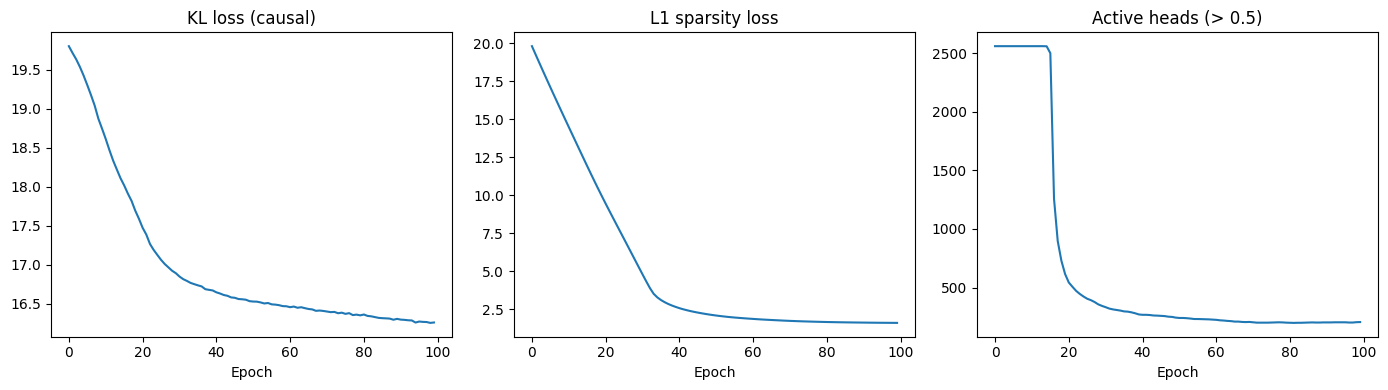

In [ ]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history.loss_causal)
axes[0].set_title("KL loss (causal)")
axes[0].set_xlabel("Epoch")

axes[1].plot(history.loss_sparse)
axes[1].set_title("L1 sparsity loss")
axes[1].set_xlabel("Epoch")

axes[2].plot(history.n_active)
axes[2].set_title("Active heads (> 0.5)")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## Mask heatmap

2026-03-18 23:22:59 matplotlib.colorbar DEBUG    locator: <matplotlib.ticker.AutoLocator object at 0x7faed036ce90>


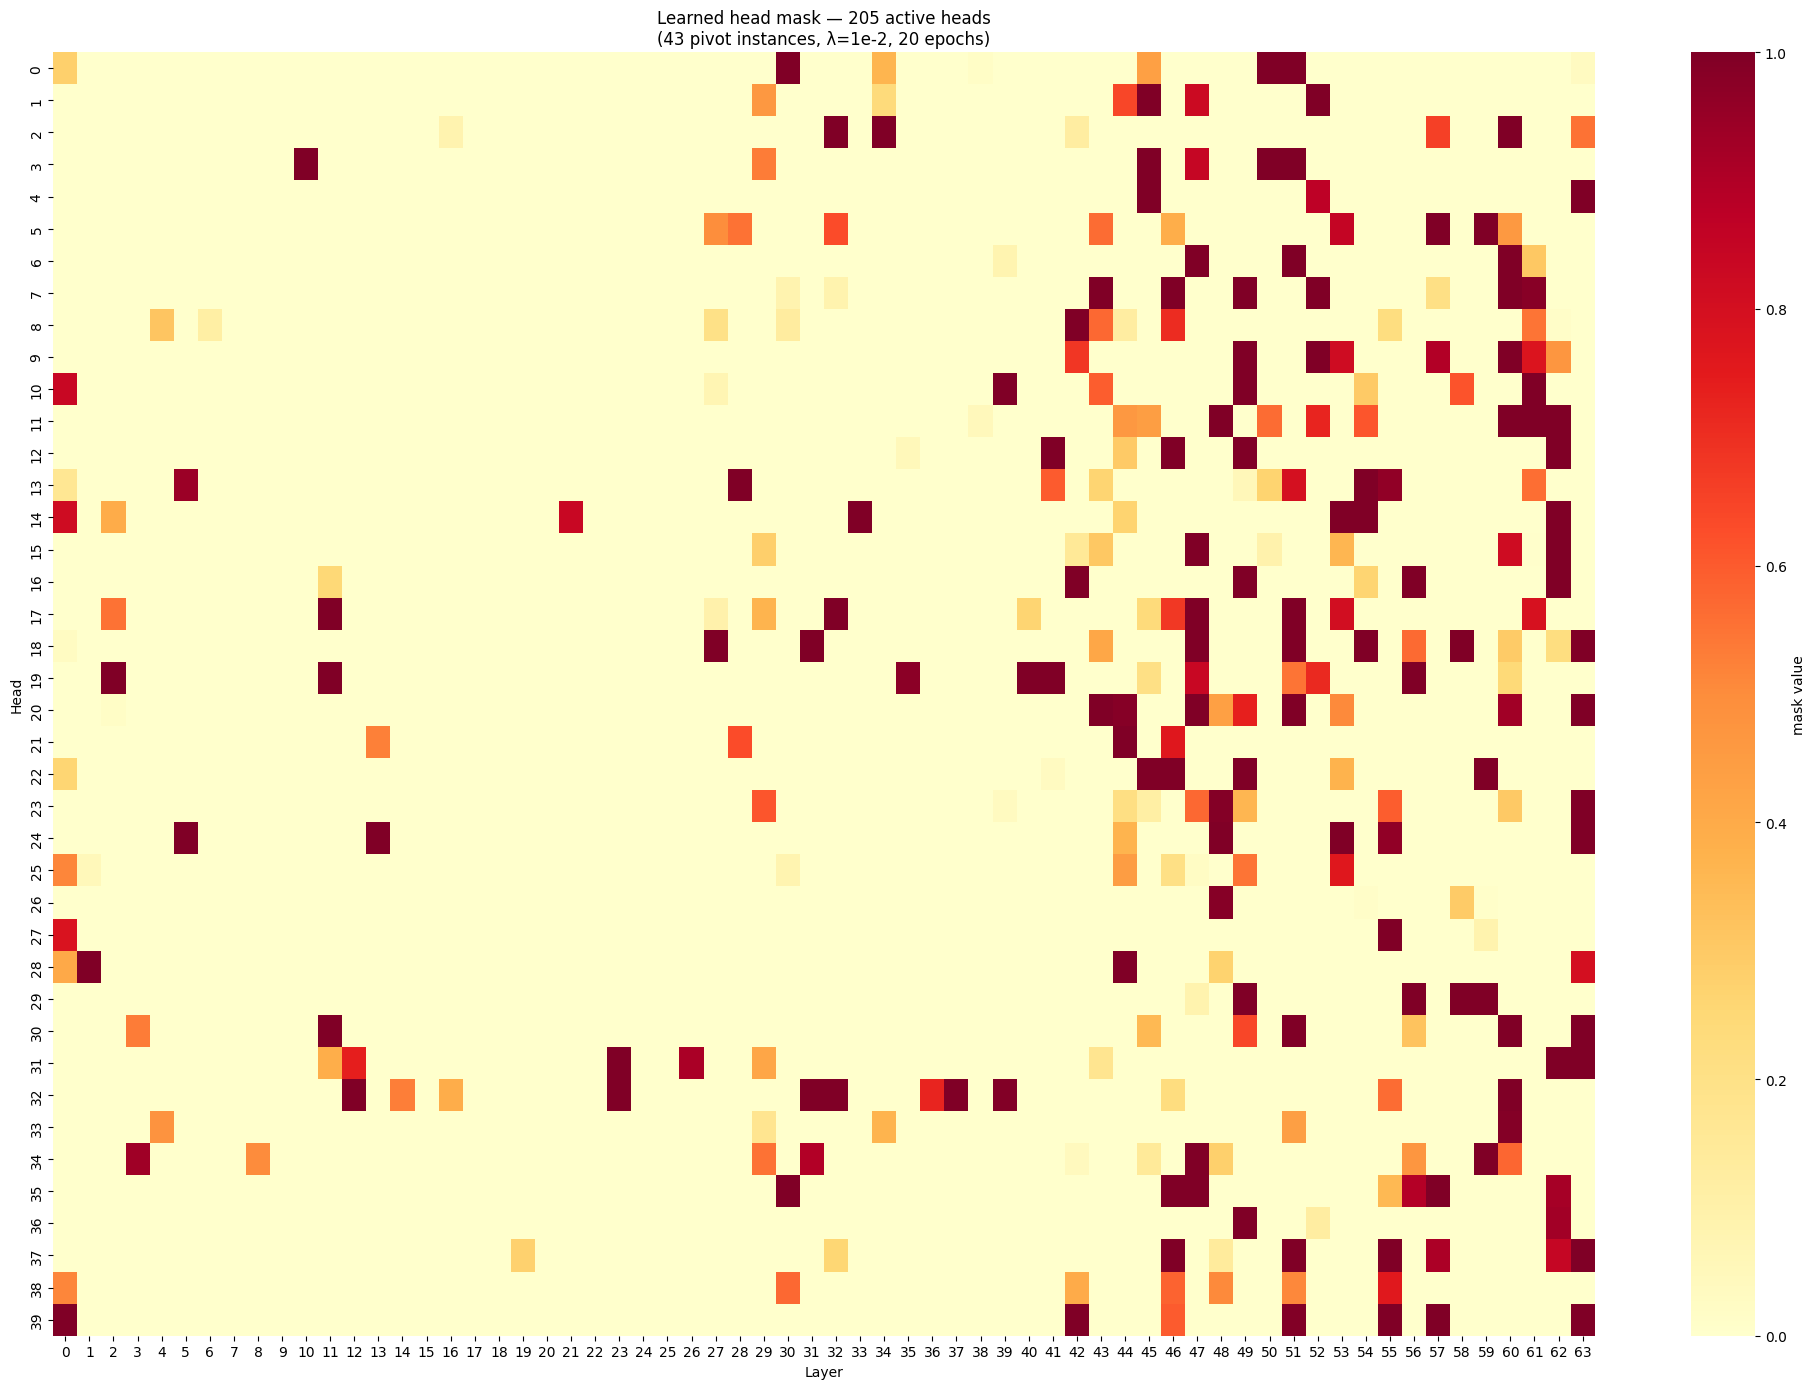


Top 10 heads by mask value:
  layer=59 head=22: 1.0000
  layer=1 head=28: 1.0000
  layer=49 head=10: 1.0000
  layer=45 head=22: 1.0000
  layer=48 head=24: 1.0000
  layer=30 head=0: 1.0000
  layer=54 head=14: 1.0000
  layer=31 head=32: 1.0000
  layer=54 head=13: 1.0000
  layer=59 head=5: 1.0000


In [ ]:
mask_vals = mask.values.detach().cpu().numpy()  # (n_layers_tested, n_heads)
import numpy as np

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    mask_vals.T, ax=ax, cmap="YlOrRd", vmin=0, vmax=1,
    xticklabels=[str(l) for l in LAYERS],
    yticklabels=range(n_heads),
    cbar_kws={"label": "mask value"},
)
ax.set_title(
    f"Learned head mask — {mask.n_active()} active heads\n"
    f"({len(pivot_instances)} pivot instances, λ=1e-2, 20 epochs)"
)
ax.set_xlabel("Layer")
ax.set_ylabel("Head")
plt.tight_layout()
plt.show()

print("\nTop 10 heads by mask value:")
flat = mask_vals.flatten()
for idx in np.argsort(flat)[::-1][:10]:
    li, h = divmod(int(idx), n_heads)
    print(f"  layer={LAYERS[li]} head={h}: {mask_vals[li, h]:.4f}")

## Sparsity sweep: λ vs. n_active vs. KL (Pareto frontier)

17:14:02 INFO src.goals.head_loc_attn — train_head_mask: 40L × 40H = 1600 mask params | 10 instances | 20 epochs | lr=0.01 λ=0.001
17:14:04 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.6388  sparse=1.5710  total=5.2098  n_active=1600
17:14:14 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1130  sparse=1.4074  total=3.5204  n_active=1574
17:14:27 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7670  sparse=1.2269  total=2.9938  n_active=1357
17:14:39 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5683  sparse=1.0787  total=2.6470  n_active=1185
17:14:51 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4358  sparse=0.9634  total=2.3993  n_active=1037
17:14:51 INFO src.goals.head_loc_attn — train_head_mask done: 1037 active heads → [(20, 3), (20, 4), (20, 5), (20, 11), (20, 15), (20, 18), (20, 25), (20, 27), (20, 28), (20, 33), (20, 34), (20, 39), (21, 1), (21, 4), (21, 6), (21, 8), (21, 9), (21, 11), (21, 13), (21, 15), (21, 18), (21, 26), (21, 27), (21, 31), (21,

  λ=1e-03: n_active=1037  KL=1.4358


17:14:53 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5949  sparse=7.7937  total=11.3886  n_active=1600
17:15:03 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0779  sparse=6.3495  total=8.4274  n_active=1507
17:15:14 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7208  sparse=4.5194  total=6.2402  n_active=933
17:15:26 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5331  sparse=3.2795  total=4.8126  n_active=665
17:15:38 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4172  sparse=2.5283  total=3.9455  n_active=506
17:15:38 INFO src.goals.head_loc_attn — train_head_mask done: 506 active heads → [(21, 32), (22, 29), (23, 6), (23, 23), (23, 26), (23, 31), (23, 35), (25, 38), (26, 9), (26, 27), (26, 31), (27, 8), (27, 10), (27, 17), (27, 18), (27, 19), (27, 21), (27, 23), (28, 4), (28, 5), (28, 12), (28, 13), (28, 17), (28, 21), (28, 23), (28, 24), (28, 25), (29, 1), (29, 2), (29, 4), (29, 17), (29, 18), (29, 19), (29, 22), (29, 23), (29, 31), (29, 39), (30, 0),

  λ=5e-03: n_active= 506  KL=1.4172


17:15:40 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5640  sparse=15.5110  total=19.0750  n_active=1600
17:15:49 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0515  sparse=11.7952  total=13.8468  n_active=1445
17:16:01 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7356  sparse=7.0230  total=8.7586  n_active=647
17:16:13 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5843  sparse=4.2879  total=5.8722  n_active=388
17:16:24 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4716  sparse=2.9599  total=4.4315  n_active=265
17:16:24 INFO src.goals.head_loc_attn — train_head_mask done: 265 active heads → [(23, 6), (27, 10), (27, 17), (27, 18), (28, 5), (28, 13), (29, 1), (29, 18), (29, 19), (29, 23), (30, 0), (30, 8), (30, 23), (30, 25), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 31), (31, 32), (31, 34), (32, 1), (32, 3), (32, 8), (32, 13), (32, 25), (32, 26), (32, 32), (32, 33), (33, 26), (33, 30), (33, 34), (34, 3), (34, 4), (34, 22), (34, 25

  λ=1e-02: n_active= 265  KL=1.4716


17:16:27 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5192  sparse=30.8728  total=34.3920  n_active=1600
17:16:36 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1125  sparse=21.8097  total=23.9222  n_active=1349
17:16:48 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.8070  sparse=10.2562  total=12.0632  n_active=381
17:17:00 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.6782  sparse=4.9416  total=6.6198  n_active=202
17:17:13 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.6196  sparse=3.2284  total=4.8480  n_active=134
17:17:13 INFO src.goals.head_loc_attn — train_head_mask done: 134 active heads → [(27, 10), (29, 1), (29, 18), (30, 8), (30, 23), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 32), (31, 34), (32, 3), (33, 34), (34, 22), (34, 25), (35, 13), (35, 39), (38, 0), (38, 7), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (39, 34), (40, 3), (40, 8), (40, 11), (40, 13), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (42, 11), (43, 5)

  λ=2e-02: n_active= 134  KL=1.6196


17:17:15 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5004  sparse=76.7545  total=80.2549  n_active=1600
17:17:25 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.3505  sparse=49.4677  total=51.8182  n_active=1125
17:17:37 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=2.0425  sparse=15.5258  total=17.5683  n_active=139
17:17:52 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=2.0015  sparse=5.2949  total=7.2964  n_active=79
17:18:04 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.9817  sparse=3.4552  total=5.4369  n_active=64
17:18:04 INFO src.goals.head_loc_attn — train_head_mask done: 64 active heads → [(30, 8), (30, 35), (31, 18), (31, 32), (38, 0), (39, 8), (39, 9), (39, 31), (39, 32), (43, 15), (44, 21), (45, 1), (45, 3), (45, 17), (45, 18), (45, 31), (46, 7), (46, 8), (46, 12), (46, 19), (46, 20), (46, 25), (46, 35), (46, 39), (47, 8), (47, 32), (47, 33), (47, 34), (48, 24), (48, 25), (48, 26), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 15), (49, 16),

  λ=5e-02: n_active=  64  KL=1.9817


17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSansMandaic-Regular.ttf', name='Noto Sans Mandaic', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/freefont/FreeMonoBoldOblique.ttf', name='FreeMono', style='oblique', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/tlwg/TlwgTypewriter-Oblique.otf', name='Tlwg Typewriter', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/ipafont-mincho/ipamp.ttf', name='IPAPMincho', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matpl

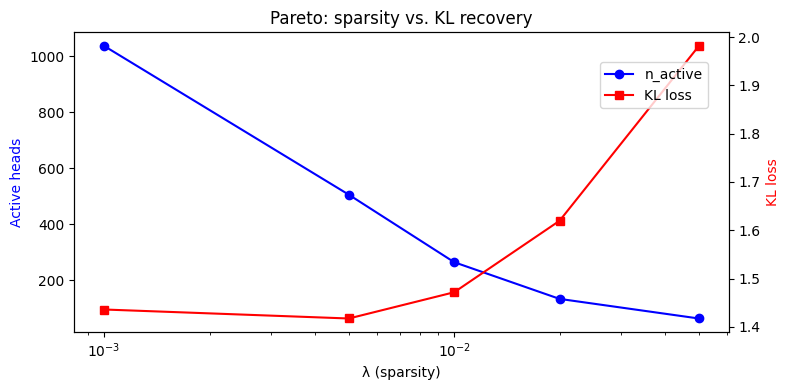

In [ ]:
# lambdas = [1e-3, 5e-3, 1e-2, 2e-2, 5e-2]
lambdas = [1, 5, 10, 20, 50, 75, 100]
pareto = []

for lam in lambdas:
    m, h = train_head_mask(mt, pivot_caches, layers=LAYERS, n_epochs=20, lr=1e-2, lambda_sparse=lam)
    pareto.append((lam, m.n_active(), h.loss_causal[-1]))
    print(f"  λ={lam:.0e}: n_active={m.n_active():4d}  KL={h.loss_causal[-1]:.4f}")

lams, n_acts, kls = zip(*pareto)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.semilogx(lams, n_acts, "b-o", label="n_active")
ax2.semilogx(lams, kls, "r-s", label="KL loss")
ax1.set_xlabel("λ (sparsity)")
ax1.set_ylabel("Active heads", color="b")
ax2.set_ylabel("KL loss", color="r")
ax1.set_title("Pareto: sparsity vs. KL recovery")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.85))
plt.tight_layout()
plt.show()

---
## Load saved mask (from `train_head_mask.py`)

Use this section when loading a mask trained by the script rather than training inline above.

In [11]:
import os
import torch
from src.goals.head_loc_attn import HeadMask

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
selected_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(selected_heads)}")
print(f"  Selected heads: {selected_heads}")

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

In [12]:
mask.values.shape

torch.Size([64, 40])

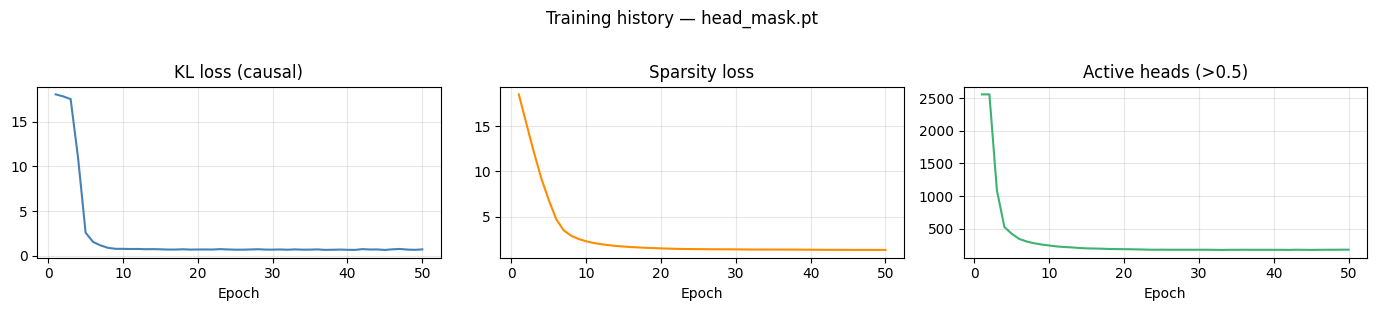

In [14]:
# Training curves from the checkpoint
from matplotlib import pyplot as plt
import numpy as np

plt.rcdefaults()

h = ckpt["history"]
xs = np.arange(1, len(h["loss_total"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(xs, h["loss_causal"],  color="steelblue");  axes[0].set_title("KL loss (causal)")
axes[1].plot(xs, h["loss_sparse"],  color="darkorange"); axes[1].set_title("Sparsity loss")
axes[2].plot(xs, h["n_active"],     color="mediumseagreen"); axes[2].set_title("Active heads (>0.5)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.suptitle(f"Training history — {os.path.basename(MASK_PATH)}", y=1.02)
plt.tight_layout()
plt.show()

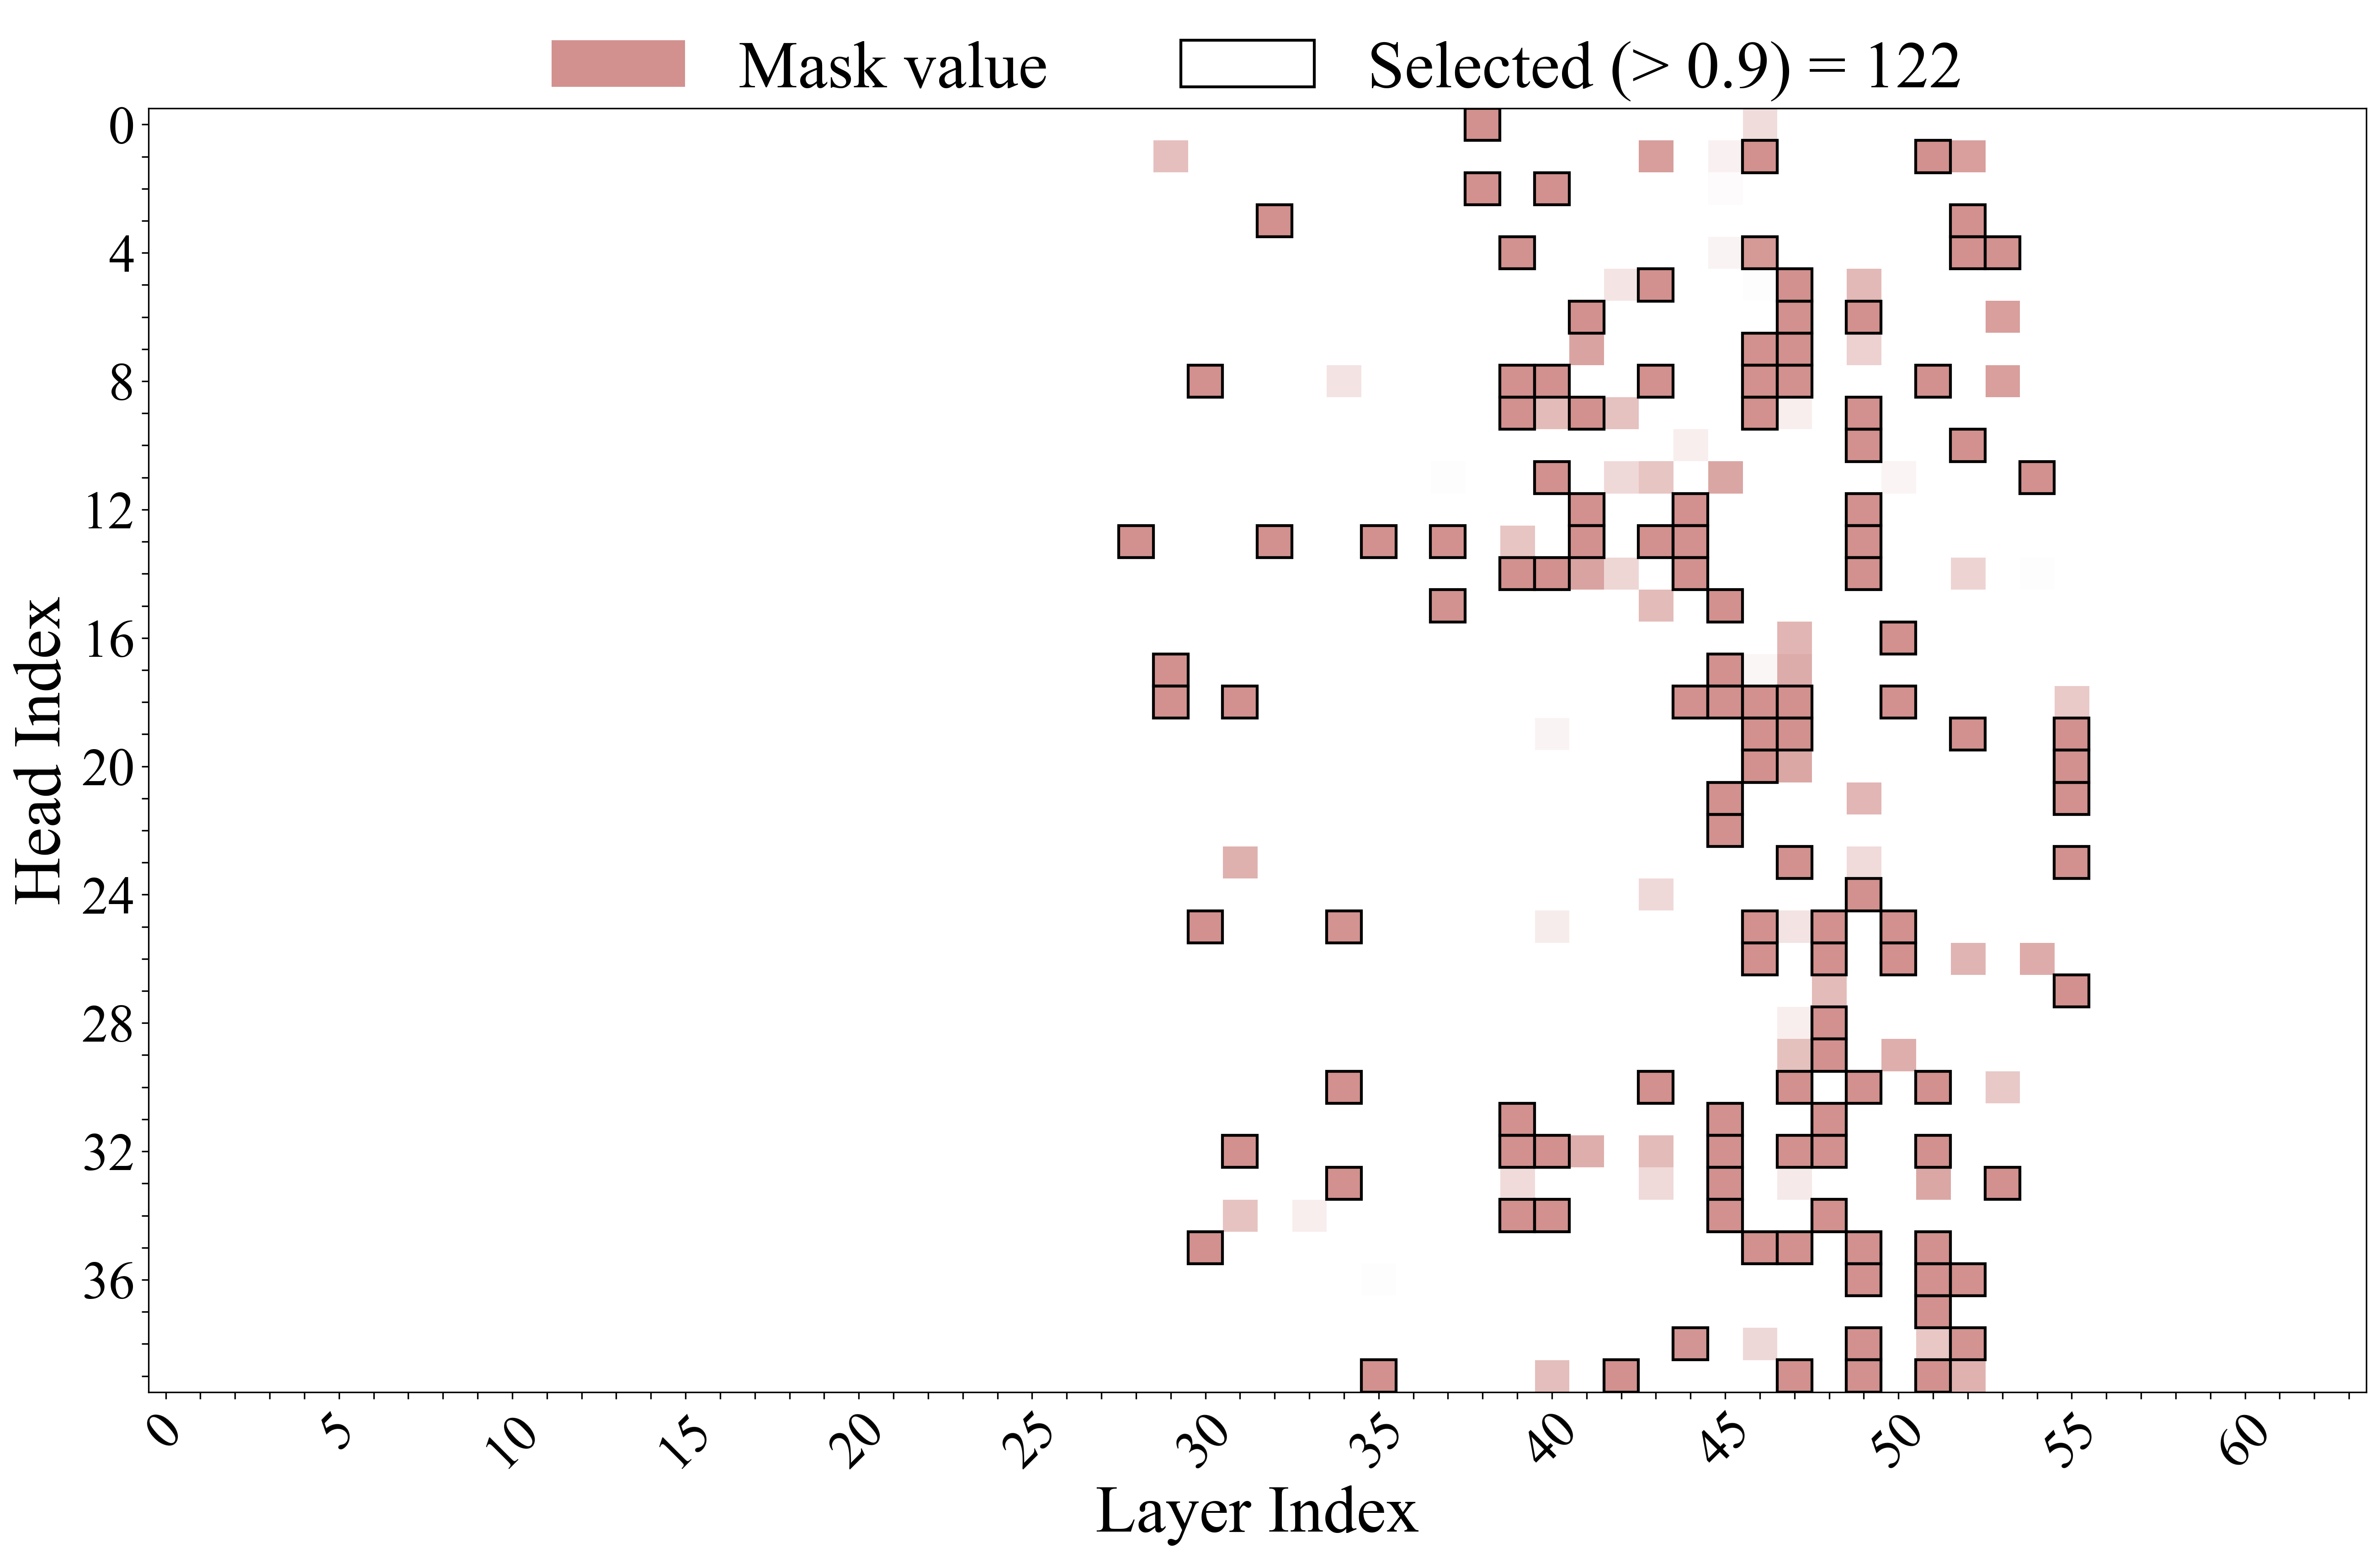

In [16]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in selected_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {threshold}) = {len(selected_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


---
## Attention pattern visualization for selected heads

`get_attention_matrices` runs one forward pass with `output_attentions=True` and returns
an `AttentionInformation` object: `.attention_matrices` is `(n_layers, n_heads, seq, seq)`.

`visualize_attn_matrix` uses **circuitsvis** to show which source tokens the last query
token (or any `q_index`) attends to for a given `(layer, head)`.

The cells below visualize:
1. Each head in `selected_heads` on the **source** (C++) prompt.
2. Each head on the **destination** (Python) prompt — shows what changes after patching.

In [19]:
from src.attention import get_attention_matrices, visualize_attn_matrix
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick a pivot instance to inspect — change IDX to explore others
# VIS_IDX = 0
# pair_v, pi_v = pivot_instances[VIS_IDX]

pair_v, pi_v = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
][0]  # Just pick the first matching instance

src_prompt_v = build_cpp_prompt(
    mt, ds.get_sample(pair_v.source_predicate), include_docstring=True
)
dest_prompt_v = build_python_prompt(
    mt,
    ds.get_sample(pair_v.destination_predicate),
    pivot_prefix=pi_v.pivot_prefix,
    include_docstring=True,
)
targ_prompt_v = build_python_prompt(
    mt,
    ds.get_sample(pair_v.source_predicate),  # source_predicate = Python target
    pivot_prefix=pi_v.pivot_prefix,
    include_docstring=True,
)

print(f"Pair: {pair_v.destination_predicate!r} ← {pair_v.source_predicate!r}")
print(
    f"Pivot prefix: {pi_v.pivot_prefix!r}  |  target token: {pi_v.target_top_token!r}"
)
print(f"\nActive heads ({len(selected_heads)}): {selected_heads}")

# One forward pass each — output_attentions=True (eager mode required)
attn_src = get_attention_matrices(src_prompt_v, mt, value_weighted=True)
attn_dest = get_attention_matrices(dest_prompt_v, mt, value_weighted=True)
attn_targ = get_attention_matrices(targ_prompt_v, mt, value_weighted=True)

Pair: 'is_lower' ← 'is_palindrome'
Pivot prefix: 's == s'  |  target token: '[::-'

Active heads (122): [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29), (48, 31), (48, 32), (48, 34), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 14), (49, 24), (49, 30),

In [20]:
top_heads = sorted(
    selected_heads, key=lambda x: mask.values[LAYERS.index(x[0]), x[1]], reverse=True
)
for layer_idx, head_idx in top_heads:
    mask_val = mask.values[LAYERS.index(layer_idx), head_idx].item()
    print(f"Layer {layer_idx} Head {head_idx} (mask={mask_val:.4f}):")

Layer 28 Head 13 (mask=1.0000):
Layer 29 Head 17 (mask=1.0000):
Layer 29 Head 18 (mask=1.0000):
Layer 30 Head 8 (mask=1.0000):
Layer 30 Head 25 (mask=1.0000):
Layer 30 Head 35 (mask=1.0000):
Layer 31 Head 18 (mask=1.0000):
Layer 31 Head 32 (mask=1.0000):
Layer 32 Head 3 (mask=1.0000):
Layer 32 Head 13 (mask=1.0000):
Layer 34 Head 30 (mask=1.0000):
Layer 34 Head 33 (mask=1.0000):
Layer 35 Head 13 (mask=1.0000):
Layer 35 Head 39 (mask=1.0000):
Layer 38 Head 0 (mask=1.0000):
Layer 38 Head 2 (mask=1.0000):
Layer 39 Head 9 (mask=1.0000):
Layer 39 Head 14 (mask=1.0000):
Layer 39 Head 31 (mask=1.0000):
Layer 39 Head 32 (mask=1.0000):
Layer 39 Head 34 (mask=1.0000):
Layer 40 Head 2 (mask=1.0000):
Layer 40 Head 8 (mask=1.0000):
Layer 40 Head 11 (mask=1.0000):
Layer 40 Head 32 (mask=1.0000):
Layer 40 Head 34 (mask=1.0000):
Layer 41 Head 6 (mask=1.0000):
Layer 41 Head 9 (mask=1.0000):
Layer 41 Head 12 (mask=1.0000):
Layer 41 Head 13 (mask=1.0000):
Layer 42 Head 39 (mask=1.0000):
Layer 43 Head 5 (

In [42]:
# # Visualize each selected head on the C++ source prompt (last-token query)
# # What does this head attend to when the model processes the C++ goal signal?

# print("=" * 80)
# print("ATTENTION PATTERNS — C++ source prompt (last token query)")
# print("=" * 80)

# for layer, head in top_heads[10:15]:
#     mask_val = mask.values[LAYERS.index(layer), head].item()
#     print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
#     mat = attn_src.get_attn_matrix(layer, head)
#     visualize_attn_matrix(mat, attn_src.tokenized_prompt, q_index=-1, start_from=0)

In [37]:
aggregated_src_attn = []
for layer, head in top_heads[:40]:
    aggregated_src_attn.append(torch.Tensor(attn_src.get_attn_matrix(layer, head)))

aggregated_src_attn = torch.stack(
    aggregated_src_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_src_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(mean_attn, attn_src.tokenized_prompt, q_index=-1, start_from=0)

In [18]:
# # Same heads on the Python destination prompt — what does the dest model attend to?
# # Comparing src vs dest attention for the same head reveals what the patch is changing.

# print("=" * 80)
# print("ATTENTION PATTERNS — Python destination prompt (last token query)")
# print("=" * 80)

# for layer, head in top_heads[:5]:
#     mask_val = mask.values[LAYERS.index(layer), head].item()
#     print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
#     mat = attn_dest.get_attn_matrix(layer, head)
#     visualize_attn_matrix(mat, attn_dest.tokenized_prompt, q_index=-1, start_from=0)

In [19]:
aggregated_dest_attn = []
for layer, head in top_heads[:40]:
    aggregated_dest_attn.append(torch.Tensor(attn_dest.get_attn_matrix(layer, head)))

aggregated_dest_attn = torch.stack(
    aggregated_dest_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_dest_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(
    mean_attn, attn_dest.tokenized_prompt, q_index=-1, start_from=0
)  # (n_selected_heads, seq_len, seq_len)

In [20]:
# # Visualize each selected head on the C++ source prompt (last-token query)
# # What does this head attend to when the model processes the C++ goal signal?

# print("=" * 80)
# print("ATTENTION PATTERNS — python target prompt (last token query)")
# print("=" * 80)

# for layer, head in top_heads[:5]:
#     mask_val = mask.values[LAYERS.index(layer), head].item()
#     print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
#     mat = attn_targ.get_attn_matrix(layer, head)
#     visualize_attn_matrix(mat, attn_targ.tokenized_prompt, q_index=-1, start_from=0)

In [21]:
aggregated_target_attn = []
for layer, head in top_heads[:40]:
    aggregated_target_attn.append(torch.Tensor(attn_targ.get_attn_matrix(layer, head)))

aggregated_target_attn = torch.stack(
    aggregated_target_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_target_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(
    mean_attn, attn_targ.tokenized_prompt, q_index=-1, start_from=0
)  # (n_selected_heads, seq_len, seq_len)

## Selecting the failed validation samples

In [ ]:
import random
from src.utils import experiment_utils
from src.goals.head_loc_attn import augment_pivot_caches, cache_pivot_data

experiment_utils.set_seed(1234)

ds = HeadLocDataset.load(model_name="Qwen2.5-Coder-32B-Instruct")
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]
random.shuffle(pivot_instances)

validation_set = pivot_instances[:128]
val_pivot_cache = cache_pivot_data(
    mt=mt,
    pivot_instances=validation_set,
    ds=ds,
    layers=LAYERS,
    include_docstring=True,
    precompute=False,
    cache_batch_size=64,
)

_aug_val_caches = augment_pivot_caches(
    mt=mt,
    pivot_caches=val_pivot_cache,
    include_docstring=True,
    cache_batch_size=64,
)


2026-03-23 21:20:02 src.utils.experiment_utils INFO     setting all seeds to 1234
2026-03-23 21:20:02 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/Qwen2.5-Coder-32B-Instruct.json
2026-03-23 21:20:02 src.goals.head_loc_attn INFO     cache_pivot_data: 128 instances | precompute=False | cache_batch_size=64
2026-03-23 21:20:04 src.goals.head_loc_attn DEBUG      targ probs: 64/128
2026-03-23 21:20:06 src.goals.head_loc_attn DEBUG      targ probs: 128/128
2026-03-23 21:20:06 src.goals.head_loc_attn DEBUG      Building cache 1/128: is_strictly_sorted ← all_positive prefix='True and all'
2026-03-23 21:20:06 src.goals.head_loc_attn DEBUG      Building cache 2/128: is_upper ← is_digit_string prefix='all(c.is'
2026-03-23 21:20:06 src.goals.head_loc_attn DEBUG      Building cache 3/128: is_palindrome ← ends_with_vowel prefix='not not s.lower()[-1'
2026-03-23 21:20:06 src.goals.head_loc_attn DEBUG      Building cache 4/

In [44]:
cache_sample.__dict__.keys()

dict_keys(['pivot_instance', 'dest_prompt', 'log_p_target', 'per_head_deltas', 'src_sample', 'dest_sample', 'src_prompt', 'src_head_vals'])

In [43]:
IDX = 121
cache_sample = _aug_val_caches[IDX]
rich_print("---- Source Prompt ----")
rich_print(f"[white]{cache_sample.src_prompt}[/white]")

rich_print("---- Destination Prompt ----")
rich_print(f"{cache_sample.dest_prompt}")

cache_sample.pivot_instance

---- Source Prompt ----

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make 
sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if every element in data is even.
bool allEven(vector<int> data) { return 

---- Destination Prompt ----

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make 
sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_same(data: list) -> bool:
    """Return True if all elements in data are equal."""
    return False or not

PivotInstance(pivot_prefix='False or not', dest_top_token=' lst', target_top_token=' any')

In [36]:
import torch
from src.goals.head_loc_attn import (
    get_o_proj_inputs_batch,
    forward_with_src_replacement,
)
from src.tokens import prepare_input
from src.utils.metrics import recall as recall_metric
from tqdm.auto import tqdm


all_predictions: list[list[str]] = []
all_targets: list[str] = []

for cache in tqdm(_aug_val_caches):
    dest_inputs = prepare_input([cache.dest_prompt], tokenizer=mt)

    if cache.src_head_vals is not None:
        src_hv = cache.src_head_vals  # (L, n_embd) — precomputed
    else:
        src_o = get_o_proj_inputs_batch(mt, [cache.src_prompt], layers=LAYERS)
        src_hv = torch.stack([src_o[ly][0] for ly in LAYERS])  # (L, n_embd)

    logits = forward_with_src_replacement(
        mt, dest_inputs, src_hv, mask, layers=LAYERS
    )  # (vocab,)
    top_k_ids = logits.topk(5).indices.tolist()
    top_k_toks = [mt.tokenizer.decode([i]) for i in top_k_ids]
    all_predictions.append(top_k_toks)
    all_targets.append(cache.pivot_instance.target_top_token)

recall_metric(all_predictions, all_targets)

  0%|          | 0/128 [00:00<?, ?it/s]

[0.796875, 0.9140625, 0.9453125, 0.9609375, 0.9609375]

In [37]:
all_predictions[:5], all_targets[:5]

([['(x', '(element', '(isinstance', '(item', '(elem'],
  ['upper', 'alpha', 'numeric', 'alnum', 'decimal'],
  [']', ':]', ':].', '].', ':s'],
  ['(x', '(element', '(value', '(item', '(num'],
  ['2', '3', '1', ' num', ' ==']],
 ['(x', 'numeric', ']', '(x', '3'])

In [65]:
failed_at_1 = [
    idx for idx, (preds, target) in enumerate(zip(all_predictions, all_targets))
    if target != preds[0]
]
success_at_1 = sorted(list(set(range(len(all_predictions))) - set(failed_at_1)))
logger.info(f"Recall@1: {len(success_at_1)}/{len(all_predictions)} = {len(success_at_1)/len(all_predictions):.4f} | failed {len(failed_at_1)} cases")

2026-03-23 22:07:05 __main__ INFO     Recall@1: 103/128 = 0.8047 | failed 25 cases


In [39]:
rich_print(_aug_val_caches[0])

PivotCache(
    pivot_instance=PivotInstance(
        pivot_prefix='True and all',
        dest_top_token='(lst',
        target_top_token='(x'
    ),
    dest_prompt='<|im_start|>system\nYou are a helpful assistant proficient in programming. When 
completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside 
the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function 
below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_strictly_sorted(lst: list[int]) -> bool:\n  
"""Return True if lst is sorted in strictly increasing order (no equal adjacent elements)."""\n    
return True and all',
    log_p_target=tensor([-21.3990, -21.1178, -20.2428,  ..., -23.0259, -23.0259, -23.0259]),
    per_head_deltas=None,
    src_sample=SinglePredicateSample(
        predicate_name='all_positive',
        variable_type='list[int]',
        variable_name='lst',
        python_incomplete_code='def all_positive(lst: list[int]) -> bool:\n    return',
        cpp_incomplete_code='bool allPositive(vector<int> lst) { return',
        unit_tests=[
            ([1, 2, 3], True),
            ([5, 10, 15], True),
            ([1, 2, 3, 4], True),
            ([1, 0, 3], False),
            ([2, 4, -1], False),
            ([1, 2, 0], False)
        ],
        function_name='all_positive',
        docstring='Return True if every element in lst is greater than zero.',
        augmentation=None
    ),
    dest_sample=SinglePredicateSample(
        predicate_name='is_strictly_sorted',
        variable_type='list[int]',
        variable_name='lst',
        python_incomplete_code='def is_strictly_sorted(lst: list[int]) -> bool:\n    return',
        cpp_incomplete_code='bool isStrictlySorted(vector<int> lst) { return',
        unit_tests=[
            ([1, 2, 3], True),
            ([1, 2, 3, 4, 5], True),
            ([1, 2], True),
            ([1, 1, 2], False),
            ([3, 2, 1], False),
            ([1, 3, 2], False)
        ],
        function_name='is_strictly_sorted',
        docstring='Return True if lst is sorted in strictly increasing order (no equal adjacent 
elements).',
        augmentation=None
    ),
    src_prompt='<|im_start|>system\nYou are a helpful assistant proficient in programming. When 
completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside 
the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Prolog predicate 
below.<|im_end|>\n<|im_start|>assistant\n<code>\n% Return True if every element in lst is greater 
than zero.\nall_positive(Lst) :- ',
    src_head_vals=None
)

## Qualitative Analysis

In [27]:
selected_instances = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_instances)

10

In [ ]:
import torch
from rich.console import Console
from rich.table import Table

from src.goals.head_loc_attn import (
    HeadMask,
    forward_with_src_replacement,
    get_o_proj_inputs_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ──────────────────
_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in selected_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads ({100 * binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

METRIC = "logit"  # "logit" or "prob"
MAX_NEW_TOKENS = 32
PATCH_ALL_TOKENS = True  # True  → patch every generated token
# False → patch only the pivot (first token), then greedy

_STOP_IDS = {mt.tokenizer.eos_token_id} | set(
    mt.tokenizer.encode("\n", add_special_tokens=False)
)


def _greedy_continue(mt, input_ids, attention_mask, max_new_tokens):
    """Plain greedy generation — no patching."""
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            out = mt._model(input_ids=input_ids, attention_mask=attention_mask)
            next_tok = int(out.logits[0, -1].argmax())
            generated.append(next_tok)
            if next_tok in _STOP_IDS:
                break
            input_ids = torch.cat(
                [input_ids, torch.tensor([[next_tok]], device=input_ids.device)], dim=1
            )
            attention_mask = torch.cat(
                [
                    attention_mask,
                    torch.ones(
                        (1, 1), dtype=attention_mask.dtype, device=attention_mask.device
                    ),
                ],
                dim=1,
            )
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def _patched_generate(mt, dest_inputs, src_head_vals, mask, layers, max_new_tokens):
    """Greedy generation with head patching applied at every token position."""
    input_ids = dest_inputs["input_ids"].clone()
    attention_mask = dest_inputs["attention_mask"].clone()
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
            # forward_with_src_replacement patches the last token position each step,
            # so as the sequence grows the intervention follows the generation frontier.
            logits = forward_with_src_replacement(
                mt, inputs, src_head_vals, mask, layers
            )
            next_tok = int(logits.argmax())
            generated.append(next_tok)
            if next_tok in _STOP_IDS:
                break
            input_ids = torch.cat(
                [input_ids, torch.tensor([[next_tok]], device=input_ids.device)], dim=1
            )
            attention_mask = torch.cat(
                [
                    attention_mask,
                    torch.ones(
                        (1, 1), dtype=attention_mask.dtype, device=attention_mask.device
                    ),
                ],
                dim=1,
            )
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


Binary mask: 118 active heads / 5120 total heads (2.30%)


In [29]:
import logging
from src.goals.head_loc_module import _top5_str
from src.utils.metrics import recall, AggregateMetric
from src.goals.head_loc_pivot import (
    build_cpp_prompt,
    build_python_prompt,
    build_java_prompt,
    build_haskell_prompt,
    build_prolog_prompt,
    build_rust_prompt,
)

logger = logging.getLogger(__name__)
console = Console(width=130, highlight=False)

K_RECALL = 5  # recall@k to report

# Accumulate across instances
_dest_preds_all = []
_patched_preds_all = []
_targets_all = []
_ie_all = []

for idx, (pair, pi) in enumerate(selected_instances):
    src_sample = ds.get_sample(pair.source_predicate)
    dest_sample = ds.get_sample(pair.destination_predicate)
    targ_sample = ds.get_sample(pair.source_predicate)
    pfx = f"return {pi.pivot_prefix}" if pi.pivot_prefix else ""

    # src_prompt  = build_cpp_prompt(mt, src_sample, include_docstring=True)
    # src_prompt = build_java_prompt(mt, src_sample, include_docstring=True)
    src_prompt = build_rust_prompt(mt, src_sample, include_docstring=True)
    dest_prompt = build_python_prompt(
        mt, dest_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
    )
    targ_prompt = build_python_prompt(
        mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
    )
    src_predicate_name = pair.source_predicate
    dest_predicate_name = pair.destination_predicate

    # pfx = '""" Check if'
    # dest_prompt = dest_prompt.split('"""')[0] + pfx
    # targ_prompt = targ_prompt.split('"""')[0] + pfx
    # ---------------------------------------------------------------------------


# # for idx in failed_at_1:
# for idx in success_at_1:
#     val_cache = _aug_val_caches[idx]
#     src_prompt = val_cache.src_prompt
#     dest_prompt = val_cache.dest_prompt
#     pi = val_cache.pivot_instance
#     targ_prompt = build_python_prompt(
#         mt, val_cache.src_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
#     )
#     pfx = f"return {pi.pivot_prefix}" if pi.pivot_prefix else ""
#     dest_predicate_name = val_cache.dest_sample.predicate_name
#     src_predicate_name = val_cache.src_sample.predicate_name
#     # ---------------------------------------------------------------------------

    logger.debug(
        f"\n{'=' * 80}\nInstance {idx}: {dest_predicate_name} ← {src_predicate_name}  prefix={pi.pivot_prefix!r}"
    )
    logger.debug(f"[src prompt]\n{src_prompt}")
    logger.debug(f"[dest prompt]\n{dest_prompt}")
    logger.debug(f"[targ prompt]\n{targ_prompt}")

    target_tok_id = mt.tokenizer.encode(pi.target_top_token, add_special_tokens=False)[
        0
    ]

    dest_inputs = prepare_input([dest_prompt], tokenizer=mt)
    targ_inputs = prepare_input([targ_prompt], tokenizer=mt)

    # ── Source head vals (src-only forward pass) ──────────────────────────────
    src_o = get_o_proj_inputs_batch(mt, [src_prompt], LAYERS)
    src_head_vals = torch.stack([src_o[ly][0] for ly in LAYERS])  # (L, n_embd)

    # ── Three forward passes ──────────────────────────────────────────────────
    with torch.no_grad():
        logits_dest = mt._model(**dest_inputs).logits[0, -1]
        logits_targ = mt._model(**targ_inputs).logits[0, -1]
        logits_patched = forward_with_src_replacement(
            mt, dict(dest_inputs), src_head_vals, binary_mask, LAYERS
        )

    score_dest = get_score(logits_dest, target_tok_id, metric=METRIC)
    score_targ = get_score(logits_targ, target_tok_id, metric=METRIC)
    score_patched = get_score(logits_patched, target_tok_id, metric=METRIC)
    ie = (score_patched - score_dest) / (score_targ - score_dest + 1e-8)

    logger.debug(
        f"[dest]    top5: {_top5_str(mt, logits_dest, METRIC)}  target({pi.target_top_token!r})={score_dest:.4f}"
    )
    logger.debug(
        f"[targ]    top5: {_top5_str(mt, logits_targ, METRIC)}  target({pi.target_top_token!r})={score_targ:.4f}"
    )
    logger.debug(
        f"[patched] top5: {_top5_str(mt, logits_patched, METRIC)}  target({pi.target_top_token!r})={score_patched:.4f}  IE={ie:.3f}"
    )

    # ── Accumulate ───────────────────────────────────────────────────────────
    def _topk_toks(logits, k):
        return [mt.tokenizer.decode([i]) for i in logits.topk(k).indices.tolist()]

    _dest_preds_all.append(_topk_toks(logits_dest, K_RECALL))
    _patched_preds_all.append(_topk_toks(logits_patched, K_RECALL))
    _targets_all.append(pi.target_top_token)
    _ie_all.append(ie)

    # ── Generation ───────────────────────────────────────────────────────────
    src_gen = _greedy_continue(
        mt,
        prepare_input([src_prompt], tokenizer=mt)["input_ids"],
        prepare_input([src_prompt], tokenizer=mt)["attention_mask"],
        MAX_NEW_TOKENS,
    )
    dest_gen = _greedy_continue(
        mt,
        dest_inputs["input_ids"].clone(),
        dest_inputs["attention_mask"].clone(),
        MAX_NEW_TOKENS,
    )
    targ_gen = _greedy_continue(
        mt,
        targ_inputs["input_ids"].clone(),
        targ_inputs["attention_mask"].clone(),
        MAX_NEW_TOKENS,
    )

    if PATCH_ALL_TOKENS:
        # Patch at every generated token position.
        patched_gen = _patched_generate(
            mt,
            dict(dest_inputs),
            src_head_vals,
            binary_mask,
            LAYERS,
            MAX_NEW_TOKENS,
        )
    else:
        # Patch only the pivot (first token), then continue greedily.
        patched_first_tok = int(logits_patched.argmax())
        _dev = dest_inputs["input_ids"].device
        _ids_p = torch.cat(
            [
                dest_inputs["input_ids"],
                torch.tensor([[patched_first_tok]], device=_dev),
            ],
            dim=1,
        )
        _msk_p = torch.cat(
            [
                dest_inputs["attention_mask"],
                torch.ones(
                    (1, 1), dtype=dest_inputs["attention_mask"].dtype, device=_dev
                ),
            ],
            dim=1,
        )
        patched_gen = mt.tokenizer.decode([patched_first_tok]) + _greedy_continue(
            mt, _ids_p, _msk_p, MAX_NEW_TOKENS - 1
        )

    # ── Per-instance table ────────────────────────────────────────────────────
    patch_mode = "patch-all" if PATCH_ALL_TOKENS else "patch-pivot"
    console.print(
        f"\n[bold cyan]Instance {idx}[/bold cyan]  "
        f"[bright_green]{dest_predicate_name}[/bright_green] ← [bright_red]{src_predicate_name}[/bright_red]  "
        f"prefix={pi.pivot_prefix!r}  target_tok=[bright_magenta][bold]{pi.target_top_token!r}[/bold][/bright_magenta]  [{patch_mode}]"
    )
    table = Table(highlight=False, show_header=True, pad_edge=False, box=None)
    table.add_column("run", style="bright_cyan", width=12)
    table.add_column(METRIC, style="salmon1", width=8, justify="right")
    table.add_column("IE", style="bright_magenta", width=7, justify="right")
    table.add_column("generation", width=85)
    table.add_row("src (C++)", "—", "—", f"{src_gen}")
    table.add_row(
        "dest (base)",
        f"{score_dest:.4f}",
        "—",
        f"[bright_yellow]{pfx}[/bright_yellow]{dest_gen}",
    )
    table.add_row(
        "targ (sky)",
        f"{score_targ:.4f}",
        "—",
        f"[bright_yellow]{pfx}[/bright_yellow]{targ_gen}",
    )
    table.add_row(
        "patched",
        f"{score_patched:.4f}",
        f"{ie:.3f}",
        f"[bright_yellow]{pfx}[/bright_yellow]{patched_gen}",
    )
    console.print(table)

# ── Aggregate summary ─────────────────────────────────────────────────────────
recall_dest = recall(_dest_preds_all, _targets_all)
recall_patched = recall(_patched_preds_all, _targets_all)
ie_agg = AggregateMetric.aggregate(_ie_all)

summary = Table(
    title=f"Summary  (N={len(_targets_all)})", highlight=False, show_header=True
)
summary.add_column("run", style="cyan")
summary.add_column("IE  mean±se", style="salmon1", justify="right")
for k in range(1, K_RECALL + 1):
    summary.add_column(f"recall@{k}", style="bright_yellow", justify="right")
summary.add_row(
    "dest (baseline)",
    "—",
    *[f"{recall_dest[k - 1]:.3f}" for k in range(1, K_RECALL + 1)],
)
summary.add_row(
    "patched",
    str(ie_agg),
    *[f"{recall_patched[k - 1]:.3f}" for k in range(1, K_RECALL + 1)],
)
console.print()
console.print(summary)


2026-03-26 12:25:04 __main__ DEBUG    
Instance 0: is_lower ← is_palindrome  prefix='s == s'
2026-03-26 12:25:05 __main__ DEBUG    [src prompt]
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|eot_id|><|start_header_id|>user<|end_header_id|>

Complete the Rust function below.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

<code>
/// Return True if s reads the same forwards and backwards.
fn is_palindrome(s: &str) -> bool {
    return
2026-03-26 12:25:05 __main__ DEBUG    [dest prompt]
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctn

2026-03-26 12:25:05 __main__ DEBUG    [dest]    top5: [ "'.lower'" (27.62), "'.case'" (22.12), "' lower'" (20.00), "'lower'" (18.25), "'-case'" (17.25) ]  target('[::-')=12.0000
2026-03-26 12:25:05 __main__ DEBUG    [targ]    top5: [ "'[::-'" (32.75), "'[-'" (18.12), "'.reverse'" (18.00), "'[:'" (17.00), "'['" (15.62) ]  target('[::-')=32.7500
2026-03-26 12:25:05 __main__ DEBUG    [patched] top5: [ "'[::-'" (27.00), "'.case'" (16.75), "'.lower'" (15.06), "'-case'" (14.38), "' Casey'" (14.31) ]  target('[::-')=27.0000  IE=0.723


Instance 0  is_lower ← is_palindrome  prefix='s == s'  target_tok='[::-'

run              logit       IE  generation                                                                           
src (C++)            —        —   s.chars().zip(s.chars().rev()).all(|(a, b)| a == b);                                
                                 }                                                                                    
                                                                                                                      
                                 fn main() {                                                                          
                                     println!("{}", is_palindrome("                                                   
dest (base)    12.0000        —  return s == s.lower()                                                                
                                 </code>                                                                              
                                                                                                                      
                                 However, I don't see a function provided for me to complete. Please provide the      
                                 function you would like me to complete, and I                                        
targ (sky)     32.7500        —  return s == s[::-1]                                                                  
                                 </code>                                                                              
                                                                                                                      
                                 This function uses Python's slicing feature to reverse the string `s`. The `[::-1]`  
                                 slice means "start at the                                                            
patched        27.0000    0.723  return s == s[::-1]                                                                  
                                 </code>                                                                              
                                                                                                                      
                                 However, the above function does not check if the string is the same forwards and    
                                 backwards, but rather checks if the string is the

2026-03-26 12:25:31 __main__ DEBUG    
Instance 1: is_lower ← is_palindrome  prefix='bool(s == s'
2026-03-26 12:25:31 __main__ DEBUG    [src prompt]
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|eot_id|><|start_header_id|>user<|end_header_id|>

Complete the Rust function below.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

<code>
/// Return True if s reads the same forwards and backwards.
fn is_palindrome(s: &str) -> bool {
    return
2026-03-26 12:25:31 __main__ DEBUG    [dest prompt]
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical cor

Instance 1  is_lower ← is_palindrome  prefix='bool(s == s'  target_tok='[::-'

... (22 outputs left out)

2026-03-26 12:30:08 __main__ DEBUG    
Instance 9: is_upper ← is_palindrome  prefix='False or s == s'
2026-03-26 12:30:08 __main__ DEBUG    [src prompt]
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|eot_id|><|start_header_id|>user<|end_header_id|>

Complete the Rust function below.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

<code>
/// Return True if s reads the same forwards and backwards.
fn is_palindrome(s: &str) -> bool {
    return
2026-03-26 12:30:08 __main__ DEBUG    [dest prompt]
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical

Instance 9  is_upper ← is_palindrome  prefix='False or s == s'  target_tok='[::-'

run              logit       IE  generation                                                                           
src (C++)            —        —   s.chars().zip(s.chars().rev()).all(|(a, b)| a == b);                                
                                 }                                                                                    
                                                                                                                      
                                 fn main() {                                                                          
                                     println!("{}", is_palindrome("                                                   
dest (base)    11.1250        —  return False or s == s.upper()                                                       
                                 </code>                                                                              
                                                                                                                      
                                 However, I can simplify the function as follows:                                     
                                                                                                                      
                                 <code>                                                                               
                                 def is_upper(s: str) -> bool:                                                        
                                     """Return True                                                                   
targ (sky)     28.6250        —  return False or s == s[::-1]                                                         
                                 </code>                                                                              
                                                                                                                      
                                 However, the above function can be simplified as follows:                            
                                                                                                                      
                                 <code>                                                                               
                                 def is_palindrome(s: str) -> bool:                                                   
patched        25.5000    0.821  return False or s == s[::-1]                                                         
                                     # The above line is incorrect as it checks if the string is a palindrome.        
                                     # Here is the correct implementation:                                            
                                     return s ==

                                    Summary  (N=10)                                     
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ run             ┃ IE  mean±se ┃ recall@1 ┃ recall@2 ┃ recall@3 ┃ recall@4 ┃ recall@5 ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━┩
│ dest (baseline) │           — │    0.000 │    0.000 │    0.000 │    0.000 │    0.000 │
│ patched         │ 0.78 ± 0.02 │    1.000 │    1.000 │    1.000 │    1.000 │    1.000 │
└─────────────────┴─────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

## Causality Test: Adversarial Prefill Persistance

In [30]:
from src.functional import free_gpu_cache

_STOP_IDS = (
    {mt.tokenizer.eos_token_id}
    | set(mt.tokenizer.encode("\n", add_special_tokens=False))
    | set(mt.tokenizer.encode("\n\n", add_special_tokens=False))
)


def _patched_generate_with_sampling(
    mt,
    dest_inputs,
    src_head_vals,
    mask,
    layers,
    max_new_tokens,
    n_gen_per_prompt: int = 1,
    do_sample: bool = False,
    temperature: float = 1.0,
    alpha: float = 1.0,
) -> list[str]:
    """Generation with head patching applied at every token position.

    All n_gen_per_prompt sequences are batched into a single forward pass per
    step. Stopped sequences are removed from the active batch, so the batch
    shrinks over time but never needs padding — all active sequences always
    share the same sequence length.

    Args:
        mt: ModelandTokenizer.
        dest_inputs: Tokenized destination prompt (batch=1 dict).
        src_head_vals: (n_layers_tested, n_embd) source head values.
        mask: HeadMask whose values gate the per-head interpolation.
        layers: List of layer indices to patch.
        max_new_tokens: Maximum tokens to generate.
        n_gen_per_prompt: Number of independent generation runs (default 1).
        do_sample: If True, sample; if False (default), greedy decode.
        temperature: Softmax temperature used when do_sample=True (default 1.0).

    Returns:
        List of decoded strings, length == n_gen_per_prompt.
    """
    # Ensure src is 2D (L, n_embd) for uniform handling below
    src_2d = src_head_vals if src_head_vals.dim() == 2 else src_head_vals.squeeze(0)

    # Per-sequence state as lists of 1D tensors so sequences can grow independently
    init_ids = dest_inputs["input_ids"][0]  # (prompt_len,)
    init_amask = dest_inputs["attention_mask"][0]  # (prompt_len,)
    ids = [init_ids.clone() for _ in range(n_gen_per_prompt)]
    amask = [init_amask.clone() for _ in range(n_gen_per_prompt)]
    generated = [[] for _ in range(n_gen_per_prompt)]
    active = list(range(n_gen_per_prompt))

    with torch.no_grad():
        for _ in range(max_new_tokens):
            if not active:
                break

            n_active = len(active)
            # Stack active sequences — all have identical length at this step
            batch_ids = torch.stack([ids[i] for i in active])  # (n_active, seq_len)
            batch_amask = torch.stack([amask[i] for i in active])  # (n_active, seq_len)
            inputs = {"input_ids": batch_ids, "attention_mask": batch_amask}

            # Expand src to (n_active, L, n_embd) — same source for all sequences
            src_exp = src_2d.unsqueeze(0).expand(n_active, -1, -1)
            logits = forward_with_src_replacement(mt, inputs, src_exp, mask, layers, alpha)
            # logits: (n_active, vocab_size)

            if do_sample:
                probs = torch.softmax(logits.float() / temperature, dim=-1)
                next_toks = torch.multinomial(probs, num_samples=1).squeeze(
                    1
                )  # (n_active,)
            else:
                next_toks = logits.argmax(dim=-1)  # (n_active,)

            newly_done = []
            for j, i in enumerate(active):
                tok = int(next_toks[j])
                generated[i].append(tok)
                if tok in _STOP_IDS:
                    newly_done.append(i)
                else:
                    tok_t = torch.tensor([tok], device=ids[i].device)
                    ids[i] = torch.cat([ids[i], tok_t])
                    amask[i] = torch.cat(
                        [
                            amask[i],
                            torch.ones(1, dtype=amask[i].dtype, device=amask[i].device),
                        ]
                    )

            active = [i for i in active if i not in newly_done]

    free_gpu_cache()
    return [
        mt.tokenizer.decode(g, skip_special_tokens=True).rstrip() for g in generated
    ]


In [37]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset
import copy


single_pred_dataset = IncompleteCodeDataset.load_dataset()
for sample in single_pred_dataset:
    print(sample.function_name)

PRED_NAME = "is_palindrome"

single_pred_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0])
single_pred_sample.code = single_pred_sample.code.replace("s: str", "word: str")
single_pred_sample.code = single_pred_sample.code.replace("is_palindrome", "check_palindrome")
single_pred_sample.function_name = "check_palindrome"

rich_print(single_pred_sample)

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
# prefill = "1 -"
prefill = "5"
if supports_chat_template(mt):
    adv_prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    adv_prompt = single_pred_sample.code + prefill

prefill_idx = adv_prompt.index(prefill.strip())
rich_print(
    f'"[white]{adv_prompt[:prefill_idx]}[/white][bright_yellow]{adv_prompt[prefill_idx:]}[/bright_yellow]"'
)

2026-03-26 12:33:02 src.goals.data INFO     Loaded 17 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json
is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def check_palindrome(word: str) -> bool:\n    return True if ',
    unit_tests=[('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)],
    prefills={
        'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'],
        'adversarial': ['not', 'not (', 's +', '3', '1 +'],
        'inconsequential': ['bool(', 'True and', 'False or', '0 +']
    },
    function_name='check_palindrome',
    augmentation=None
)

"<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make 
sure to have all codes inside the <code> </code> tags.<|eot_id|><|start_header_id|>user<|end_header_id|>

Write a function in python that checks if a string is a palindrome.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

<code>
def check_palindrome(word: str) -> bool:
    return True if 5"

In [38]:
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
)

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=adv_prompt,
    n_generations=128,
    patches=None,
    label="baseline",
)

2026-03-26 12:33:03 scripts.causality.adversarial_persistence DEBUG    Generating 128 samples (baseline)...


2026-03-26 12:33:25 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 128 outputs...
2026-03-26 12:33:25 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 0/128 passed (0.000)


In [39]:
# rich_print(eval_results_filtered.generations[0])

In [41]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def check_palindrome(word: str) -> bool:
    return True if """

                                                             Code Completion Results                                                              
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill            ┃ Logic                                                 ┃ Verdict ┃ Unit Tests                                       ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "5" │ "5 > len(word) > 0 and word == word[::-1] else False" │ FAILED  │ check_palindrome(racecar)=False, expected True ✗ │      │
│                    │                                                       │         │ check_palindrome(hello)=False ✓                  │      │
│                    │                                                       │         │ check_palindrome()=False, expected True ✗        │      │
│                    │                                                       │         │ check_palindrome(a)=True ✓                       │      │
│                    │                                                       │         │ check_palindrome(ab)=False ✓                     │      │
│                    │                                                       │         │ check_palindrome(aba)=True ✓                     │      │
│                    │                                                       │         │ check_palindrome(abba)=True ✓                    │      │
├────────────────────┼───────────────────────────────────────────────────────┼─────────┼──────────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 > len(word) > 0 and word == word[::-1] else False" │ FAILED  │ check_palindrome(racecar)=False, expected True ✗ │      │
│                    │                                                       │         │ check_palindrome(hello)=False ✓                  │      │
│                    │                                                       │         │ check_palindrome()=False, expected True ✗        │      │
│                    │                                                       │         │ check_palindrome(a)=True ✓                       │      │
│                    │                                                       │         │ check_palindrome(ab)=False ✓                     │      │
│                    │                                                       │         │ check_palindrome(aba)=True ✓                     │      │
│                    │                                                       │         │ check_palindrome(abba)=True ✓                    │      │
├────────────────────┼───────────────────────────────────────────────────────┼─────────┼──────────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 > len(word) > 0 and word == word[::-1] else False" │ FAILED  │ check_palindrome(racecar)=False, expected True ✗ │      │
│                    │                                                       │         │ check_palindrome(hello)=False ✓                  │      │
│                    │                                                       │         │ check_palindrome()=False, expected True ✗        │      │
│                    │                                                       │         │ check_palindrome(a)=True ✓                       │      │
│                    │                                                       │         │ check_palindrome(ab)=False ✓                     │      │
│                    │                                                       │         │ check_palindrome(aba)=True ✓                     │      │
│                    │                                                       │         │ check_palindrome(abba)=True ✓                    │      │
├────────────────────┼─────────

Summary: 0/128 passed, 128/128 failed

In [42]:
if supports_chat_template(mt):
    bare_prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code,
    )
else:
    bare_prompt = single_pred_sample.code

rich_print(
    f'"[white]{bare_prompt}[/white]"'
)

src_o = get_o_proj_inputs_batch(mt, [bare_prompt], LAYERS)
src_head_vals = torch.stack([src_o[ly][0] for ly in LAYERS])  # (L, n_embd)

print(src_head_vals.shape)

"<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make 
sure to have all codes inside the <code> </code> tags.<|eot_id|><|start_header_id|>user<|end_header_id|>

Write a function in python that checks if a string is a palindrome.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

<code>
def check_palindrome(word: str) -> bool:
    return True if"

torch.Size([80, 8192])


In [43]:
patched_gen = _patched_generate_with_sampling(
    mt,
    dest_inputs=prepare_input([adv_prompt], tokenizer=mt),
    src_head_vals=src_head_vals,
    mask=binary_mask,
    layers=LAYERS,
    max_new_tokens=32,
    n_gen_per_prompt=128,
    do_sample=True,
    temperature=1.0,
    alpha=1.0,
)

In [45]:
from src.goals.data import CodeGenerations, Code
from scripts.causality.adversarial_persistence import run_evaluation_timed

generations = CodeGenerations(
    sample=single_pred_sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="steering_eval",
            full_prompt=adv_prompt,
            lm_generation=gen,
        )
        for gen in patched_gen
    ],
)

eval_context = {"label": "steering", "prefill": prefill}
eval_results = run_evaluation_timed(
    result=generations,
    function_name=single_pred_sample.function_name,
    code_stop_tag="</code>",
    context=eval_context,
    eval_timeout=5,
    eval_timeout_log=None
)

eval_results_filtered = deepcopy(eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

True
True
True


"""def check_palindrome(word: str) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill            ┃ Logic                                                                         ┃ Verdict ┃ Unit Tests                                                                     ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "5" │ "5 * (word == word[::-1]) else word == word[::-1]"                            │ PASSED  │                                                                                │      │
├────────────────────┼───────────────────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 > len(word) == len(word[::-1]) else False"                                 │ FAILED  │ check_palindrome(racecar)=False, expected True ✗                               │      │
│                    │                                                                               │         │ check_palindrome(hello)=False ✓                                                │      │
│                    │                                                                               │         │ check_palindrome()=True ✓                                                      │      │
│                    │                                                                               │         │ check_palindrome(a)=True ✓                                                     │      │
│                    │                                                                               │         │ check_palindrome(ab)=True, expected False ✗                                    │      │
│                    │                                                                               │         │ check_palindrome(aba)=True ✓                                                   │      │
│                    │                                                                               │         │ check_palindrome(abba)=True ✓                                                  │      │
├────────────────────┼───────────────────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 <= len(word) <= 20 else "Error: String should have a length between 5 and  │ FAILED  │ check_palindrome(racecar)=True ✓                                               │      │
│                    │ 20""                                                                          │         │ check_palindrome(hello)=True, expected False ✗                                 │      │
│                    │                                                                               │         │ check_palindrome()=Error: String should have a length between 5 and 20,        │      │
│                    │                                                                               │         │ expected True ✗                                                                │      │
│                    │                                                                               │         │ check_palindrome(a)=Error: String should have a length between 5 and 20,       │      │
│                    │                                                                               │         │ expected True ✗                                                     

Summary: 15/128 passed, 113/128 failed

## Ablations

In [17]:
from src.goals.functional import supports_chat_template, apply_chat_template

from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset
import copy


single_pred_dataset = IncompleteCodeDataset.load_dataset()
for sample in single_pred_dataset:
    print(sample.function_name)

PRED_NAME = "is_palindrome"

single_pred_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0])
single_pred_sample.code = single_pred_sample.code.replace("s: str", "word: str")
single_pred_sample.code = single_pred_sample.code.replace("is_palindrome", "check_palindrome")
single_pred_sample.function_name = "check_palindrome"

rich_print(single_pred_sample)

if supports_chat_template(mt):
    bare_prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code,
    )
else:
    bare_prompt = single_pred_sample.code

rich_print(
    f'"[white]{bare_prompt}[/white]"'
)

2026-03-26 17:58:19 src.goals.data INFO     Loaded 17 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def check_palindrome(word: str) -> bool:\n    return True if ',
    unit_tests=[
        ('racecar', True),
        ('hello', False),
        ('', True),
        ('a', True),
        ('ab', False),
        ('aba', True),
        ('abba', True)
    ],
    prefills={
        'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'],
        'adversarial': ['not', 'not (', 's +', '3', '1 +'],
        'inconsequential': ['bool(', 'True and', 'False or', '0 +']
    },
    function_name='check_palindrome',
    augmentation=None
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def check_palindrome(word: str) -> bool:
    return True if "

In [21]:
from src.functional import get_module_nnsight
from src.tokens import prepare_input
from src.attention import visualize_attn_matrix

bare_tokenized = prepare_input(bare_prompt, tokenizer=mt)
logger.info(f"{bare_tokenized['input_ids'].shape=}, {bare_tokenized['attention_mask'].shape=}")

_val_heads = [top_heads[11]]  # Just visualize the single most important head for this instance
print("_val_heads:", _val_heads)
layer_to_head_mapping = {}

base_attn_matrices = {}

for layer_idx, head_idx in _val_heads:
    if layer_idx not in layer_to_head_mapping:
        layer_to_head_mapping[layer_idx] = []
        base_attn_matrices[layer_idx] = {}
    layer_to_head_mapping[layer_idx].append(head_idx)

with mt.trace(bare_tokenized) as trace:
    for layer_idx in layer_to_head_mapping:
        attn_module = get_module_nnsight(mt, mt.attn_module_name_format.format(layer_idx))
        # print(attn_module.source.attention_interface_0.source)
        attn_weights = attn_module.source.attention_interface_0.source.to_0.output.save()
        print(f"{layer_idx}: {attn_weights.shape}")
        base_attn_matrices[layer_idx][head_idx] = attn_weights[:, head_idx, :, :].save()

    out = mt.output.logits.save()


tokens = [mt.tokenizer.decode(token) for token in bare_tokenized["input_ids"][0]]

for layer_idx, head_idx in _val_heads:
    attn_matrix = base_attn_matrices[layer_idx][head_idx]
    visualize_attn_matrix(attn_matrix, tokens, q_index=-1, start_from=0)

2026-03-26 17:58:46 __main__ INFO     bare_tokenized['input_ids'].shape=torch.Size([1, 82]), bare_tokenized['attention_mask'].shape=torch.Size([1, 82])


_val_heads: [(34, 33)]
34: torch.Size([1, 40, 82, 82])


In [22]:
from src.hooking.llama_attention import AttentionEdge

cut_edges = [
    AttentionEdge(q_idx=-1, k_idx=tok_idx) 
    # for tok_idx in range(len(tokens) - 1) # from q_idx = -1, focus on the current token, no information mixing
    for tok_idx in range(1, len(tokens)) # sink on first token
]
# cut_edges = [] # no edges cut

ablated_attn_matrices = {}


with mt.trace(bare_tokenized) as trace:
    for layer_idx in layer_to_head_mapping:
        head_indices = layer_to_head_mapping[layer_idx]
        attn_module = get_module_nnsight(mt, mt.attn_module_name_format.format(layer_idx))
        print(attn_module.source.attention_interface_0.source)
        pre_softmax_attn_weights = attn_module.source.attention_interface_0.source.nn_functional_softmax_0.input

        for head_idx in head_indices:
            for edge in cut_edges:
                pre_softmax_attn_weights[:, head_idx, edge.q_idx, edge.k_idx] = -torch.inf

        attn_weights = attn_module.source.attention_interface_0.source.to_0.output.save()
        print(f"{layer_idx}: {attn_weights.shape}")
        if layer_idx not in ablated_attn_matrices:
            ablated_attn_matrices[layer_idx] = {}
        ablated_attn_matrices[layer_idx][head_idx] = attn_weights[:, head_idx, :, :].save()

    out = mt.output.logits.save()


tokens = [mt.tokenizer.decode(token) for token in bare_tokenized["input_ids"][0]]

for layer_idx, head_idx in _val_heads:
    attn_matrix = ablated_attn_matrices[layer_idx][head_idx]
    visualize_attn_matrix(attn_matrix, tokens, q_index=-1, start_from=0)

                             * def eager_attention_forward(
                             0     module: nn.Module,
                             1     query: torch.Tensor,
                             2     key: torch.Tensor,
                             3     value: torch.Tensor,
                             4     attention_mask: torch.Tensor | None,
                             5     scaling: float,
                             6     dropout: float = 0.0,
                             7     **kwargs: Unpack[TransformersKwargs],
                             8 ):
 repeat_kv_0             ->  9     key_states = repeat_kv(key, module.num_key_value_groups)
 repeat_kv_1             -> 10     value_states = repeat_kv(value, module.num_key_value_groups)
                            11 
 key_states_transpose_0  -> 12     attn_weights = torch.matmul(query, key_states.transpose(2, 3)) * scaling
 torch_matmul_0          ->  +     ...
                            13     if attention_mask is not None:


In [23]:
from src.hooking.llama_attention import AttentionEdge


def forward_with_attn_knockout(
    mt,
    inputs: dict,
    knockout_edges: dict[tuple[int, int], list[AttentionEdge]],
    save_attn_pattern_for_heads: list[tuple[int, int]] | None = None,
) -> tuple[torch.Tensor, dict]:
    """Forward pass with specific attention edges zeroed per (layer, head).

    For each (layer, head) key in knockout_edges, the corresponding list of
    AttentionEdge(q_idx, k_idx) entries are set to -inf in the pre-softmax
    attention scores.  The mask is built outside the trace (plain torch ops),
    so only one addition node per layer enters the nnsight graph regardless of
    how many edges are specified.

    Args:
        mt: ModelandTokenizer.
        inputs: Tokenised input dict (any batch size).
        knockout_edges: Mapping from (layer_idx, head_idx) to the list of
            AttentionEdge objects whose scores should be set to -inf.
        save_attn_pattern_for_heads: If provided, save the post-intervention
            post-softmax attention pattern for each (layer, head) pair listed.
            NOTE: relies on the node named ``to_0`` being the final op before
            the attention-interface output (verified for Qwen2.5; may differ
            for other architectures).

    Returns:
        logits: (vocab,) float32 for batch=1, else (batch, vocab).
        metadata: dict with key ``'attn_patterns'`` →
            {(layer, head): (seq, seq) float32 tensor} (empty if not requested).
    """
    squeeze = inputs["input_ids"].shape[0] == 1
    seq_len = inputs["input_ids"].shape[1]
    n_heads = mt.model.config.num_attention_heads
    device  = next(mt._model.parameters()).device

    # ── Build per-layer knockout masks (outside the trace — plain torch) ──────
    layer_masks: dict[int, torch.Tensor] = {}
    for (layer, head), edges in knockout_edges.items():
        if layer not in layer_masks:
            layer_masks[layer] = torch.zeros(1, n_heads, seq_len, seq_len, device=device)
        for edge in edges:
            layer_masks[layer][0, head, edge.q_idx, edge.k_idx] = -torch.inf

    # ── Which layers need pattern saving ──────────────────────────────────────
    save_by_layer: dict[int, list[int]] = {}
    if save_attn_pattern_for_heads:
        for layer, head in save_attn_pattern_for_heads:
            save_by_layer.setdefault(layer, []).append(head)

    pattern_proxies: dict[int, object] = {}   # layer → saved proxy (full n_heads)

    # ── Trace ─────────────────────────────────────────────────────────────────
    with torch.no_grad():
        with mt.trace(inputs, scan=False, validate=False):
            for layer in set(layer_masks) | set(save_by_layer):
                attn_path = mt.attn_module_name_format.format(layer)
                attn_mod  = get_module_nnsight(mt, attn_path)
                ai        = attn_mod.source.attention_interface_0

                if layer in layer_masks:
                    # Single addition node in the graph regardless of edge count
                    softmax_node = ai.source.nn_functional_softmax_0
                    softmax_node.input = softmax_node.input + layer_masks[layer].to(softmax_node.input.device)

                if layer in save_by_layer:
                    # Save once per layer; slice per head after the trace
                    pattern_proxies[layer] = ai.source.to_0.output.save()

            logits_proxy = mt.output.logits[:, -1, :].save()

    # ── Materialise ───────────────────────────────────────────────────────────
    attn_patterns: dict[tuple[int, int], torch.Tensor] = {}
    for layer, heads in save_by_layer.items():
        full = pattern_proxies[layer]  # (batch, n_heads, seq, seq)
        for head in heads:
            pat = full[:, head, :, :]
            attn_patterns[(layer, head)] = pat[0] if squeeze else pat  # (seq, seq)

    out = logits_proxy.float()
    return (out[0] if squeeze else out), {"attn_patterns": attn_patterns}


In [24]:
import random
import numpy as np
from src.functional import get_module_nnsight

# ── GQA config (kept for other cells that reference these) ───────────────────
_n_heads    = mt.model.config.num_attention_heads
_n_kv_heads = mt.model.config.num_key_value_heads
_n_groups   = _n_heads // _n_kv_heads
_head_dim   = mt.n_embd // _n_heads


def ablate_heads_attn_sink(
    mt,
    inputs: dict,
    selected_heads: list[tuple[int, int]],
    sink_pos: int = 0,
    save_attn_pattern_for_heads: list[tuple[int, int]] | None = None,
) -> tuple[torch.Tensor, dict]:
    """Suppress selected attention heads by sinking them to ``sink_pos``.

    For each (layer, head) in selected_heads, cuts every attention edge from
    the last query position to all key positions *except* sink_pos.  The head
    can only attend to the sink token, so its o_proj contribution collapses to
    V[sink_pos] — informationally isolated from the rest of the sequence.

    Delegates to ``forward_with_attn_knockout``.

    Args:
        selected_heads: List of (layer_idx, head_idx) to ablate.
        sink_pos: Token index to preserve as the sole attention target.
            0 = first token (default), -1 = last token (self-sink).
        save_attn_pattern_for_heads: Passed through to forward_with_attn_knockout.

    Returns:
        (logits, metadata) — see forward_with_attn_knockout.
    """
    seq_len  = inputs["input_ids"].shape[1]
    sink_idx = sink_pos % seq_len  # resolve negative indices

    head_edges = {
        (layer, head): [
            AttentionEdge(q_idx=-1, k_idx=k)
            for k in range(seq_len) if k != sink_idx
        ]
        for layer, head in selected_heads
    }

    return forward_with_attn_knockout(
        mt, inputs, head_edges,
        save_attn_pattern_for_heads=save_attn_pattern_for_heads,
    )


In [25]:
mt.reset_forward()
mt.set_attn_implementation("eager")

### Validation: `forward_with_attn_knockout` — pre-softmax masking check

`forward_with_attn_knockout` hooks `nn_functional_softmax_0.input` and adds `-inf` to
the masked edges. To validate this works correctly for the attention-sink pattern we:

1. Run `ablate_heads_attn_sink` with `save_attn_pattern_for_heads` → get the actual
   post-softmax pattern from inside the nnsight graph.
2. Run a clean forward pass and save `nn_functional_softmax_0.input` (pre-softmax weights).
3. Manually apply the knockout mask to those pre-softmax weights and take `softmax`.
4. Assert the actual and expected patterns agree within bfloat16 tolerance.

As a secondary check we also compare against `LlamaAttentionPatcher` with `cut_attn_edges`
(may fail on Qwen due to architecture mismatch — that's OK, the mathematical check is authoritative).

In [26]:
LAYERS[20]

20

In [27]:
from src.hooking.llama_attention import LlamaAttentionPatcher, AttentionEdge
from src.goals.head_loc_pivot import build_python_prompt
from src.tokens import prepare_input
from baukit import get_module
import types

SINK_POS = 0  # first-token sink

# ── Pick a validation instance ─────────────────────────────────────────────────
if supports_chat_template(mt):
    val_prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code,
    )
else:
    val_prompt = single_pred_sample.code

rich_print(f'"[white]{val_prompt}[/white]"')
_val_inputs = prepare_input(val_prompt, tokenizer=mt)
seq_len = _val_inputs["input_ids"].shape[1]

_val_layer = top_heads[0][0]
_val_head  = top_heads[0][1]
_val_selected = [(_val_layer, _val_head)]

# ── Step 1: run ablation, save actual post-softmax attention pattern ───────────
mt.reset_forward()
mt.set_attn_implementation("eager")
logits_nnsight, meta = ablate_heads_attn_sink(
    mt, _val_inputs, _val_selected, sink_pos=SINK_POS,
    save_attn_pattern_for_heads=_val_selected,
)
actual_pattern = meta["attn_patterns"][(_val_layer, _val_head)]
# actual_pattern shape: (seq_len, seq_len), last row is the last-token query

rich_print(f"nnsight top-5: {[mt.tokenizer.decode([i]) for i in logits_nnsight.topk(5).indices.tolist()]}")

# ── Step 2: clean forward — save pre-softmax attention weights ─────────────────
mt.reset_forward()
mt.set_attn_implementation("eager")
with torch.no_grad():
    with mt.trace(_val_inputs, scan=False, validate=False):
        _attn_mod = get_module_nnsight(mt, mt.attn_module_name_format.format(_val_layer))
        _pre_sm_proxy = (
            _attn_mod.source
            .attention_interface_0.source
            .nn_functional_softmax_0.input.save()
        )

pre_sm = _pre_sm_proxy.float().clone()
# pre_sm shape: (1, n_heads, seq_len, seq_len)

# ── Step 3: manually apply knockout mask + softmax ─────────────────────────────
pre_sm_masked = pre_sm.clone()
sink_idx = SINK_POS % seq_len
for k in range(seq_len):
    if k != sink_idx:
        pre_sm_masked[0, _val_head, -1, k] = float("-inf")

expected_pattern = torch.softmax(pre_sm_masked[0, _val_head], dim=-1)
# expected_pattern shape: (seq_len, seq_len)

# ── Step 4: compare ────────────────────────────────────────────────────────────
math_diff = (actual_pattern.float() - expected_pattern).abs().max().item()
rich_print(f"\nMathematical validation (pre-softmax masking check):")
rich_print(f"  actual_pattern[last_q, sink_pos]   = {actual_pattern[-1, sink_idx].item():.6f}  (should be ~1.0)")
rich_print(f"  expected_pattern[last_q, sink_pos] = {expected_pattern[-1, sink_idx].item():.6f}")
rich_print(f"  max |actual - expected| = {math_diff:.6f}")

if math_diff < 1e-2:
    rich_print("[green]✓ Mathematical validation passed — nnsight pre-softmax hook is correct[/green]")
else:
    rich_print("[red]✗ Mathematical validation failed — unexpected divergence[/red]")

# ── Secondary: LlamaAttentionPatcher comparison (may fail on Qwen) ─────────────
try:
    mt.reset_forward()
    mt.set_attn_implementation("sdpa")

    knockout_edges = [
        AttentionEdge(q_idx=-1, k_idx=k)
        for k in range(seq_len) if k != sink_idx
    ]
    for layer_idx, head_idx in _val_selected:
        attn_block_name = mt.attn_module_name_format.format(layer_idx)
        attn_module = get_module(mt._model, attn_block_name)
        attn_module.forward = types.MethodType(
            LlamaAttentionPatcher(
                block_name=attn_block_name,
                cut_attn_edges={head_idx: knockout_edges},
            ),
            attn_module,
        )

    with torch.no_grad():
        logits_patcher = mt._model(**_val_inputs).logits[0, -1].float()

    max_diff = (logits_nnsight - logits_patcher).abs().max().item()
    rich_print(f"\nLlamaAttentionPatcher comparison:")
    rich_print(f"  patcher top-5: {[mt.tokenizer.decode([i]) for i in logits_patcher.topk(5).indices.tolist()]}")
    rich_print(f"  max |logits_nnsight - logits_patcher| = {max_diff:.4f}")
    if max_diff < 0.1:
        rich_print("[green]✓ Patcher agrees with nnsight[/green]")
    else:
        rich_print("[yellow]⚠ Patcher disagrees — expected for Qwen architecture mismatch[/yellow]")

except Exception as e:
    rich_print(f"\n[yellow]LlamaAttentionPatcher skipped ({type(e).__name__}: {e})[/yellow]")

finally:
    mt.reset_forward()
    mt.set_attn_implementation("eager")

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def check_palindrome(word: str) -> bool:
    return True if "

nnsight top-5: [' word', ' (', '1', 'word', '0']

Mathematical validation (pre-softmax masking check):

actual_pattern   = 1.000000  (should be ~1.0)

expected_pattern = 1.000000

max |actual - expected| = 0.001914

✓ Mathematical validation passed — nnsight pre-softmax hook is correct

LlamaAttentionPatcher comparison:

patcher top-5: [' word', ' (', '1', 'word', '0']

max |logits_nnsight - logits_patcher| = 0.1875

⚠ Patcher disagrees — expected for Qwen architecture mismatch

### Generation wrapper and experiment helpers

In [84]:
from src.goals.data import CodeGenerations, Code
from scripts.causality.adversarial_persistence import run_evaluation_timed

# ── Helpers ────────────────────────────────────────────────────────────────────

_STOP_IDS = (
    {mt.tokenizer.eos_token_id}
    | set(mt.tokenizer.encode("\n", add_special_tokens=False))
    | set(mt.tokenizer.encode("\n\n", add_special_tokens=False))
)


def _ablate_generate(
    mt,
    dest_inputs: dict,
    selected_heads: list[tuple[int, int]],
    max_new_tokens: int,
    n_gen_per_prompt: int = 1,
    do_sample: bool = True,
    temperature: float = 1.0,
    sink_pos: int = 0,
) -> list[str]:
    """Generate completions with selected attention heads ablated at every step.

    Identical batching logic to _patched_generate_with_sampling: all active
    sequences share the same sequence length at each step, so no padding is needed.

    Args:
        dest_inputs: Tokenized destination prompt (batch=1).
        selected_heads: List of (layer, head) to suppress via attention sink.
        sink_pos: 0 = first-token sink, -1 = self-sink.

    Returns:
        List of decoded strings, length == n_gen_per_prompt.
    """
    init_ids = dest_inputs["input_ids"][0]
    init_amask = dest_inputs["attention_mask"][0]
    ids = [init_ids.clone() for _ in range(n_gen_per_prompt)]
    amask = [init_amask.clone() for _ in range(n_gen_per_prompt)]
    generated = [[] for _ in range(n_gen_per_prompt)]
    active = list(range(n_gen_per_prompt))

    with torch.no_grad():
        for _ in range(max_new_tokens):
            if not active:
                break

            n_active = len(active)
            batch_ids = torch.stack([ids[i] for i in active])
            batch_amask = torch.stack([amask[i] for i in active])
            inputs = {"input_ids": batch_ids, "attention_mask": batch_amask}

            # ablate_heads_attn_sink returns (logits, metadata)
            logits, _ = ablate_heads_attn_sink(mt, inputs, selected_heads, sink_pos)
            # logits shape: (n_active, vocab) or (vocab,) — normalise
            if logits.dim() == 1:
                logits = logits.unsqueeze(0)

            if do_sample:
                probs = torch.softmax(logits.float() / temperature, dim=-1)
                next_toks = torch.multinomial(probs, num_samples=1).squeeze(1)
            else:
                next_toks = logits.argmax(dim=-1)

            newly_done = []
            for j, i in enumerate(active):
                tok = int(next_toks[j])
                generated[i].append(tok)
                if tok in _STOP_IDS:
                    newly_done.append(i)
                else:
                    tok_t = torch.tensor([tok], device=ids[i].device)
                    ids[i] = torch.cat([ids[i], tok_t])
                    amask[i] = torch.cat(
                        [
                            amask[i],
                            torch.ones(1, dtype=amask[i].dtype, device=amask[i].device),
                        ]
                    )
            active = [i for i in active if i not in newly_done]

    return [
        mt.tokenizer.decode(g, skip_special_tokens=True).rstrip() for g in generated
    ]


def _generate_normal(
    mt,
    dest_inputs: dict,
    n: int,
    do_sample: bool = True,
    temperature: float = 1.0,
    max_new_tokens: int = 64,
) -> list[str]:
    """Standard (unpatched) generation using mt._model.generate."""
    with torch.no_grad():
        out = mt._model.generate(
            **dest_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature if do_sample else 1.0,
            num_return_sequences=n,
            pad_token_id=mt.tokenizer.eos_token_id,
        )
    prompt_len = dest_inputs["input_ids"].shape[1]
    return [
        mt.tokenizer.decode(out[i, prompt_len:], skip_special_tokens=True).rstrip()
        for i in range(n)
    ]


def _pass_rate(completions: list[str], sample, pivot_prefix: str) -> float:
    """Fraction of completions that pass all unit tests (uses run_evaluation_timed)."""
    if not completions:
        return 0.0
    gens = CodeGenerations(
        sample=sample,
        generations=[
            Code(prefill=pivot_prefix, prefill_type="ablation", lm_generation=comp)
            for comp in completions
        ],
    )
    result = run_evaluation_timed(
        result=gens,
        function_name=sample.function_name,
        code_stop_tag="</code>",
        context={},
        eval_timeout=5,
        eval_timeout_log=None,
    )
    # pretty_print_eval_results(result)
    return result.summary.pass_count / result.summary.total


def _sample_random_heads(
    n: int, layers: list[int], mt, rng=None
) -> list[tuple[int, int]]:
    """Sample n heads uniformly at random from the tested layers."""
    all_heads = [
        (l, h) for l in layers for h in range(mt.model.config.num_attention_heads)
    ]
    if rng is not None:
        return rng.sample(all_heads, n)
    return random.sample(all_heads, n)

### Ablation experiment

Three conditions per pivot instance, N generations each with `do_sample=True`:
- **Skyline**: unpatched generation
- **Ablate selected**: `selected_heads` from trained mask suppressed via attention sink
- **Baseline**: same number of *random* heads suppressed (averaged over K seeds)


In [52]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset
import copy


single_pred_dataset = IncompleteCodeDataset.load_dataset()
for sample in single_pred_dataset:
    print(sample.function_name)

PRED_NAME = "is_palindrome"

single_pred_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0])
# single_pred_sample.code = single_pred_sample.code.replace("s: str", "word: str")
# single_pred_sample.code = single_pred_sample.code.replace("is_uppercase", "check_uppercase")
# single_pred_sample.function_name = "check_uppercase"

rich_print(single_pred_sample)

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
# prefill = "1 -"
# prefill = "5"
prefill = ""

if supports_chat_template(mt):
    adv_prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    adv_prompt = single_pred_sample.code + prefill

prefill_idx = adv_prompt.index(prefill.strip())
rich_print(
    f'"[white]{adv_prompt[:prefill_idx]}[/white][bright_yellow]{adv_prompt[prefill_idx:]}[/bright_yellow]"'
)

dest_inputs = prepare_input([adv_prompt], tokenizer=mt)
len(dest_inputs["input_ids"][0]), len(dest_inputs["attention_mask"][0])

2026-03-26 18:09:45 src.goals.data INFO     Loaded 17 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json
is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[
        ('racecar', True),
        ('hello', False),
        ('', True),
        ('a', True),
        ('ab', False),
        ('aba', True),
        ('abba', True)
    ],
    prefills={
        'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'],
        'adversarial': ['not', 'not (', 's +', '3', '1 +'],
        'inconsequential': ['bool(', 'True and', 'False or', '0 +']
    },
    function_name='is_palindrome',
    augmentation=None
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if "

(82, 82)

In [53]:
from src.goals.data import CodeGenerations, Code
from scripts.causality.adversarial_persistence import run_evaluation_timed
from copy import deepcopy
from src.goals.eval import pretty_print_eval_results

sky_gens = _generate_normal(mt, dest_inputs, n=16, do_sample=True, temperature=1.0)
sky_codes = CodeGenerations(
    sample=single_pred_sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="sky",
            full_prompt=adv_prompt,
            lm_generation=gen,
        )
        for gen in sky_gens
    ],
)
eval_context = {"label": "steering", "prefill": prefill}
eval_results = run_evaluation_timed(
    result=sky_codes,
    function_name=single_pred_sample.function_name,
    code_stop_tag="</code>",
    context=eval_context,
    eval_timeout=5,
    eval_timeout_log=None
)

eval_results_filtered = deepcopy(eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False


"""def is_palindrome(s: str) -> bool:
    return True if """

                                   Code Completion Results                                   
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill ┃ Logic                                             ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ sky: "" │ " s == s[::-1] else False                         │ PASSED  │            │      │
│         │                                                   │         │            │      │
│         │ # Example usage:                                  │         │            │      │
│         │ print(is_palindrome("radar"))  # Output: True     │         │            │      │
│         │ print(is_palindrome("hello"))  # Output: False"   │         │            │      │
├─────────┼───────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ sky: "" │ " s == s[::-1] else False                         │ PASSED  │            │      │
│         │                                                   │         │            │      │
│         │ # Example usage:                                  │         │            │      │
│         │ print(is_palindrome("racecar"))  # Output: True   │         │            │      │
│         │ print(is_palindrome("hello"))    # Output: False" │         │            │      │
├─────────┼───────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ sky: "" │ " s == s[::-1] else False                         │ PASSED  │            │      │
│         │                                                   │         │            │      │
│         │ # Example usage:                                  │         │            │      │
│         │ print(is_palindrome("racecar"))  # Output: True   │         │            │      │
│         │ print(is_palindrome("hello"))    # Output: False" │         │            │      │
├─────────┼───────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ sky: "" │ " s == s[::-1] else False                         │ PASSED  │            │      │
│         │                                                   │         │            │      │
│         │ # Example usage:                                  │         │            │      │
│         │ print(is_palindrome("racecar"))  # Output: True   │         │            │      │
│         │ print(is_palindrome("python"))   # Output: False" │         │            │      │
├─────────┼───────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ sky: "" │ " s == s[::-1] else False                         │ PASSED  │            │      │
│         │                                                   │         │            │      │
│         │ # Example usage:                                  │         │            │      │
│         │ print(is_palindrome("racecar"))  # Output: True   │         │            │      │
│         │ print(is_palindrome("hello"))    # Output: False" │         │            │      │
└─────────┴───────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 16/16 passed, 0/16 failed

In [37]:
import itertools

selected_heads = mask.selected_heads(LAYERS, threshold=0.9)

ablated_gens = _ablate_generate(
    mt,
    dest_inputs=dest_inputs,
    selected_heads=selected_heads,
    # selected_heads=list(
    #     itertools.product(LAYERS, range(mt.model.config.num_attention_heads))
    # ),
    n_gen_per_prompt=16,
    max_new_tokens=32,
    do_sample=True,
    temperature=1.0,
    # sink_pos=dest_inputs["input_ids"].shape[1] - 1,  # self-sink to preserve positional info but no mixing
    sink_pos=0,  # first-token sink to collapse to a single token representation and test reliance on that head for information flow
)

ablated_codes = CodeGenerations(
    sample=single_pred_sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="ablated",
            full_prompt=adv_prompt,
            lm_generation=gen,
        )
        for gen in ablated_gens
    ],
)

eval_results_ablated = run_evaluation_timed(
    result=ablated_codes,
    function_name=single_pred_sample.function_name,
    code_stop_tag="</code>",
    context={"label": "ablated", "prefill": prefill},
    eval_timeout=5,
    eval_timeout_log=None,
)
eval_results_ablated_filtered = deepcopy(eval_results_ablated)
eval_results_ablated_filtered.generations = [
    gen
    for gen in eval_results_ablated_filtered.generations
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_ablated_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                                Code Completion Results                                                 
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill     ┃ Logic                                                                    ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ ablated: "" │ " s[::-1] == s else False"                                               │ PASSED  │            │      │
├─────────────┼──────────────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ ablated: "" │ " all(isinstance(c, (int, str)) for c in s) and s == s[::-1] else False" │ PASSED  │            │      │
├─────────────┼──────────────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ ablated: "" │ " s == s[::-1] else False"                                               │ PASSED  │            │      │
├─────────────┼──────────────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ ablated: "" │ " s[::-1] == s else False"                                               │ PASSED  │            │      │
├─────────────┼──────────────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ ablated: "" │ " s[::-1] == s else False"                                               │ PASSED  │            │      │
└─────────────┴──────────────────────────────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 16/16 passed, 0/16 failed

In [38]:
rand_ablation = _ablate_generate(
    mt,
    dest_inputs=dest_inputs,
    # selected_heads=_sample_random_heads(len(selected_heads), LAYERS, mt),
    selected_heads=[],
    n_gen_per_prompt=16,
    max_new_tokens=32,
    do_sample=True,
    temperature=1.0,
    sink_pos=0,
)   

rand_ablated_codes = CodeGenerations(
    sample=single_pred_sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="rand_ablated",
            full_prompt=adv_prompt,
            lm_generation=gen,
        )
        for gen in rand_ablation        
    ],
)

eval_results_rand_ablated = run_evaluation_timed(
    result=rand_ablated_codes,
    function_name=single_pred_sample.function_name,
    code_stop_tag="</code>",
    context={"label": "rand_ablated", "prefill": prefill},
    eval_timeout=5,
    eval_timeout_log=None,
)
eval_results_rand_ablated_filtered = deepcopy(eval_results_rand_ablated)
eval_results_rand_ablated_filtered.generations = [
    gen    for gen in eval_results_rand_ablated_filtered.generations
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_rand_ablated_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                            Code Completion Results                            
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill          ┃ Logic                      ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ rand_ablated: "" │ " s == s[::-1] else False" │ PASSED  │            │      │
├──────────────────┼────────────────────────────┼─────────┼────────────┼──────┤
│ rand_ablated: "" │ " s == s[::-1] else False" │ PASSED  │            │      │
├──────────────────┼────────────────────────────┼─────────┼────────────┼──────┤
│ rand_ablated: "" │ " s == s[::-1] else False" │ PASSED  │            │      │
├──────────────────┼────────────────────────────┼─────────┼────────────┼──────┤
│ rand_ablated: "" │ " s == s[::-1] else False" │ PASSED  │            │      │
├──────────────────┼────────────────────────────┼─────────┼────────────┼──────┤
│ rand_ablated: "" │ " s == s[::-1] else False" │ PASSED  │            │      │
└──────────────────┴────────────────────────────┴─────────┴────────────┴──────┘

Summary: 16/16 passed, 0/16 failed

In [58]:
from src.goals.head_loc_attn import augment_pivot_caches

_aug_val_caches = augment_pivot_caches(
    mt=mt,
    pivot_caches=pivot_caches,
    include_docstring=True,
    cache_batch_size=64,
)

2026-03-26 18:20:51 src.goals.head_loc_attn DEBUG    augment_pivot_caches: recomputing log_p_target for 9/20 instances


2026-03-26 18:20:51 src.goals.head_loc_attn INFO     augment_pivot_caches: 20 caches augmented (9 log_p recomputed, 11 reused)


In [86]:
from rich.table import Table

# ── Experiment config ──────────────────────────────────────────────────────────
N_GEN          = 16    # completions per condition
N_RANDOM_SEEDS = 1     # random head subsets for baseline averaging
MAX_NEW_TOKENS = 32
TEMPERATURE    = 0.8
SINK_POS       = 0     # first-token attention sink

# selected_heads: list[(layer, head)] from the trained mask
# Assumes `trained_mask` and `layers` are available from earlier cells
selected_heads = mask.selected_heads(LAYERS, threshold=0.9)
n_selected = len(selected_heads)
rich_print(f"Selected heads ({n_selected}): {selected_heads[:10]}{'...' if n_selected > 10 else ''}")

# ── Evaluation subset ──────────────────────────────────────────────────────────
# Use validation caches (or all pivot_caches for a full run)
eval_subset = pivot_caches   # adjust slice for full run

# ── Main loop ──────────────────────────────────────────────────────────────────
ablation_results = []

for cache in eval_subset:
    pi = cache.pivot_instance
    dest_sample = cache.dest_sample
    if dest_sample is None:
        continue

    dest_prompt = build_python_prompt(mt, dest_sample, pi.pivot_prefix, include_docstring=True)
    dest_inputs = prepare_input(tokenizer = mt, prompts = [dest_prompt])

    # Skyline — unpatched
    sky_gens  = _generate_normal(mt, dest_inputs, N_GEN,
                                 do_sample=True, temperature=TEMPERATURE,
                                 max_new_tokens=MAX_NEW_TOKENS)
    sky_rate  = _pass_rate(sky_gens, dest_sample, pi.pivot_prefix)

    logger.info(f"{sky_rate=:.2f} | passed {int(sky_rate * N_GEN)}/{N_GEN} | prompt: {repr(dest_prompt)}")

    # Ablate selected heads
    sel_gens  = _ablate_generate(mt, dest_inputs, selected_heads, MAX_NEW_TOKENS,
                                 n_gen_per_prompt=N_GEN, do_sample=True,
                                 temperature=TEMPERATURE, sink_pos=SINK_POS)
    sel_rate  = _pass_rate(sel_gens, dest_sample, pi.pivot_prefix)
    logger.info(f"{sel_rate=:.2f} | passed {int(sel_rate * N_GEN)}/{N_GEN} | prompt: {repr(dest_prompt)}")

    # Baseline — K random head subsets of the same size
    rand_rates = []
    for seed in range(N_RANDOM_SEEDS):
        random.seed(seed)
        rand_heads = _sample_random_heads(n_selected, LAYERS, mt)
        rand_gens  = _ablate_generate(mt, dest_inputs, rand_heads, MAX_NEW_TOKENS,
                                      n_gen_per_prompt=N_GEN, do_sample=True,
                                      temperature=TEMPERATURE, sink_pos=SINK_POS)
        rand_rates.append(_pass_rate(rand_gens, dest_sample, pi.pivot_prefix))
        logger.info(f"Random baseline seed {seed}: {rand_rates[-1]:.2f} | passed {int(rand_rates[-1] * N_GEN)}/{N_GEN}")

    rand_mean = float(np.mean(rand_rates))
    drop_sel  = sky_rate - sel_rate
    drop_rand = sky_rate - rand_mean

    ablation_results.append({
        "dest":              cache.dest_sample,
        "pivot":             pi.pivot_prefix,
        "skyline":           sky_rate,
        "ablate_selected":   sel_rate,
        "ablate_random":     rand_mean,
        "drop_selected":     drop_sel,
        "drop_random":       drop_rand,
        "ratio":             drop_sel / drop_rand if drop_rand > 1e-6 else float("nan"),
    })
    rich_print(
        f"[cyan]{cache.dest_sample}[/cyan] | "
        f"sky={sky_rate:.2f} sel={sel_rate:.2f} rand={rand_mean:.2f} "
        f"drop_sel={drop_sel:+.2f} drop_rand={drop_rand:+.2f}"
    )

# ── Summary table ──────────────────────────────────────────────────────────────
tbl = Table(title=f"Ablation Results (N={N_GEN}, sink_pos={SINK_POS}, heads={n_selected})")
tbl.add_column("Dest",            style="cyan")
tbl.add_column("Pivot",           style="yellow")
tbl.add_column("Skyline",         style="white")
tbl.add_column("Ablate selected", style="red")
tbl.add_column("Ablate random",   style="magenta")
tbl.add_column("Drop sel",        style="red")
tbl.add_column("Drop rand",       style="magenta")
tbl.add_column("Ratio",           style="bold green")

for r in ablation_results:
    ratio_str = f"{r['ratio']:.2f}×" if not np.isnan(r["ratio"]) else "N/A"
    tbl.add_row(
        r['dest'].function_name, repr(r["pivot"]),
        f"{r['skyline']:.2f}",
        f"{r['ablate_selected']:.2f}",
        f"{r['ablate_random']:.2f}",
        f"{r['drop_selected']:+.2f}",
        f"{r['drop_random']:+.2f}",
        ratio_str,
    )

rich_print(tbl)

# Aggregate
ratios = [r["ratio"] for r in ablation_results if not np.isnan(r["ratio"])]
rich_print(
    f"\n[bold]Summary:[/bold] mean ratio = {np.mean(ratios):.2f}× "
    f"(drop_selected / drop_random); >1 = selected heads more important than random"
)


Selected heads (122): [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 
32), (32, 3), (32, 13)]...

2026-03-26 18:48:08 __main__ INFO     sky_rate=1.00 | passed 16/16 | prompt: '<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_palindrome(s: str) -> bool:\n    """Return True if s reads the same forwards and backwards."""\n    return s == s'
2026-03-26 18:48:31 __main__ INFO     sel_rate=1.00 | passed 16/16 | prompt: '<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_palindrome(s: str) -> bool:\n    """Return True if s reads the same forwards and backwards."""\

SinglePredicateSample(predicate_name='is_palindrome', variable_type='str', variable_name='s', 
python_incomplete_code='def is_palindrome(s: str) -> bool:\n    return', cpp_incomplete_code='bool 
isPalindrome(string s) { return', unit_tests=[('racecar', True), ('hello', False), ('a', True), 
('ab', False), ('aba', True), ('abba', True), ('abcba', True)], function_name='is_palindrome', 
docstring='Return True if s reads the same forwards and backwards.', augmentation=None) | sky=1.00 
sel=1.00 rand=1.00 drop_sel=+0.00 drop_rand=+0.00

2026-03-26 18:48:56 __main__ INFO     sky_rate=1.00 | passed 16/16 | prompt: '<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_palindrome(s: str) -> bool:\n    """Return True if s reads the same forwards and backwards."""\n    return bool(s == s'
2026-03-26 18:49:17 __main__ INFO     sel_rate=1.00 | passed 16/16 | prompt: '<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_palindrome(s: str) -> bool:\n    """Return True if s reads the same forwards and backwards

SinglePredicateSample(predicate_name='is_palindrome', variable_type='str', variable_name='s', 
python_incomplete_code='def is_palindrome(s: str) -> bool:\n    return', cpp_incomplete_code='bool 
isPalindrome(string s) { return', unit_tests=[('racecar', True), ('hello', False), ('a', True), 
('ab', False), ('aba', True), ('abba', True), ('abcba', True)], function_name='is_palindrome', 
docstring='Return True if s reads the same forwards and backwards.', augmentation=None) | sky=1.00 
sel=1.00 rand=1.00 drop_sel=+0.00 drop_rand=+0.00

2026-03-26 18:49:44 __main__ INFO     sky_rate=1.00 | passed 16/16 | prompt: '<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_palindrome(s: str) -> bool:\n    """Return True if s reads the same forwards and backwards."""\n    return not not s == s'
2026-03-26 18:50:08 __main__ INFO     sel_rate=1.00 | passed 16/16 | prompt: '<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_palindrome(s: str) -> bool:\n    """Return True if s reads the same forwards and backwa

... (34 outputs left out)

SinglePredicateSample(predicate_name='is_palindrome', variable_type='str', variable_name='s', 
python_incomplete_code='def is_palindrome(s: str) -> bool:\n    return', cpp_incomplete_code='bool 
isPalindrome(string s) { return', unit_tests=[('racecar', True), ('hello', False), ('a', True), 
('ab', False), ('aba', True), ('abba', True), ('abcba', True)], function_name='is_palindrome', 
docstring='Return True if s reads the same forwards and backwards.', augmentation=None) | sky=1.00 
sel=1.00 rand=1.00 drop_sel=+0.00 drop_rand=+0.00

                           Ablation Results (N=16, sink_pos=0, heads=122)                           
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┓
┃             ┃              ┃         ┃ Ablate      ┃ Ablate       ┃          ┃           ┃       ┃
┃ Dest        ┃ Pivot        ┃ Skyline ┃ selected    ┃ random       ┃ Drop sel ┃ Drop rand ┃ Ratio ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━┩
│ is_palindr… │ 's == s'     │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│ is_palindr… │ 'bool(s ==   │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ s'           │         │             │              │          │           │       │
│ is_palindr… │ 'not not s   │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_palindr… │ 'True and s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_palindr… │ 'False or s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_lower    │ 's == s'     │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│ is_lower    │ 'bool(s ==   │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ s'           │         │             │              │          │           │       │
│ is_lower    │ 'not not s   │ 1.00    │ 0.81        │ 1.00         │ +0.19    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_lower    │ 'True and s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_lower    │ 'False or s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_upper    │ 's == s'     │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│ is_upper    │ 'bool(s ==   │ 1.00    │ 0.94        │ 1.00         │ +0.06    │ +0.00     │ N/A   │
│             │ s'           │         │             │              │          │           │       │
│ is_upper    │ 'not not s   │ 1.00    │ 0.88        │ 1.00         │ +0.12    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_upper    │ 'True and s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_upper    │ 'False or s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_palindr… │ 's == s'     │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│ is_palindr… │ 'bool(s ==   │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ s'           │         │             │              │          │           │       │
│ is_palindr… │ 'not not s   │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_palindr… │ 'True and s  │ 1.00    │ 1.00        │ 1.00         │ +0.00    │ +0.00     │ N/A   │
│             │ == s'        │         │             │              │          │           │       │
│ is_palindr… │ 'False or s  │ 1.00    │ 1.00        │ 1.00  

/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Summary: mean ratio = nan× (drop_selected / drop_random); >1 = selected heads more important than 
random